# PROBLEMA 4: ¿Quieres saber cuánto vale tu coche?
**Autor**: Jesús Peñaranda Ibarz

El objetivo es predecir el precio de venta (`Price`) de un coche usado a partir de sus características (fabricante, modelo, estado, costes etc...):

- **a)** División train/test, tratamiento de categóricas, imputación con `KNNImputer` y PCA.
- **b)** Transformación de variables y regresión lineal (calidad, pesos y residuos).
- **c)** Regresión Ridge y LASSO: comparación de pesos y selección de variables.
- **d)** Interacciones con `PolynomialFeatures` (grado 2) y nuevo ajuste de Ridge y LASSO.

## Descripción de las variables

| Variable | Qué es | Tipo |
|---|---|---|
| Manufacturer | Marca del coche (Toyota, Ford, VW, BMW, Porsche) | Categórica nominal |
| Model | Modelo del coche (RAV4, Focus, Golf...). **Anidada en `Manufacturer`** | Categórica nominal |
| Engine size | Tamaño del motor en litros | Numérica |
| Fuel type | Tipo de combustible (gasolina, diésel, híbrido) | Categórica nominal |
| Year of manufacture | Año de fabricación | Numérica |
| Mileage | Kilómetros recorridos | Numérica |
| Price | Precio de venta (**variable objetivo**) | Numérica |
| Inspection rating | Puntuación de la inspección técnica (casi siempre 10) | Numérica |
| Tires quality | Estado de los neumáticos (0-10) | Numérica |
| Interior condition | Estado del interior (0-10) | Numérica |
| Comfort level | Nivel de confort (0-10) | Numérica |
| Sound system quality | Calidad del equipo de sonido (0-10) | Numérica |
| Model reviews score | Valoración del modelo en reseñas (0-10) | Numérica |
| Overall rating | Valoración general del coche (0-10) | Numérica |
| Independent rating | Valoración de una fuente independiente (0-10) | Numérica |
| Insurance cost | Coste del seguro (solo toma los valores 200 o 800) | Categórica binaria |
| Maintenance cost | Coste de mantenimiento | Numérica |

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from apafib import load_car_sales

sns.set_theme(style="whitegrid")

In [2]:
df = load_car_sales()
print(df.shape)
df.head()

(750, 17)


,Manufacturer,Model,Engine size,Fuel type,Year of manufacture,Mileage,Price,Inspection rating,Tires quality,Interior condition,Comfort level,Sound system quality,Model reviews score,Overall rating,Independent rating,Insurance cost,Maintenance cost
0,Toyota,RAV4,2.4,Hybrid,2020.0,21317.0,68597,10.0,7.6,8.8,7.0,8.2,7.8,8.2,10.0,800.0,300.0000
1,Ford,Focus,1.8,Petrol,2018.0,22500.0,35276,10.0,7.6,7.3,5.3,4.4,5.5,5.9,6.6,800.0,127.9000
2,Ford,Mondeo,1.6,Diesel,2013.0,79521.0,17370,10.0,8.0,7.6,5.9,4.3,3.9,6.2,6.2,800.0,123.3054
3,Toyota,Yaris,1.2,Petrol,2003.0,159534.0,3213,10.0,7.5,5.4,6.5,7.9,NaN,7.7,NaN,800.0,131.0276
4,Ford,Mondeo,1.4,Diesel,2000.0,126511.0,4832,10.0,8.0,5.4,4.9,4.9,NaN,5.5,7.1,800.0,100.0000


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   Manufacturer          750 non-null    category
 1   Model                 750 non-null    category
 2   Engine size           729 non-null    float64 
 3   Fuel type             750 non-null    category
 4   Year of manufacture   696 non-null    float64 
 5   Mileage               723 non-null    float64 
 6   Price                 750 non-null    int64   
 7   Inspection rating     745 non-null    float64 
 8   Tires quality         746 non-null    float64 
 9   Interior condition    742 non-null    float64 
 10  Comfort level         703 non-null    float64 
 11  Sound system quality  717 non-null    float64 
 12  Model reviews score   695 non-null    float64 
 13  Overall rating        723 non-null    float64 
 14  Independent rating    716 non-null    float64 
 15  Insurance cost   

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Engine size,729.0,1.74,0.69,1.0,1.40,1.60,2.00,5.0
Year of manufacture,696.0,2004.40,9.85,1984.0,1996.00,2004.00,2013.00,2022.0
Mileage,723.0,111412.10,68463.27,1197.0,57047.00,101169.00,155044.00,405205.0
Price,750.0,13472.03,15430.64,133.0,3011.25,8039.00,19422.75,131460.0
Inspection rating,745.0,9.98,0.37,1.0,10.00,10.00,10.00,10.0
Tires quality,746.0,7.77,0.59,1.0,7.50,7.80,8.10,9.3
Interior condition,742.0,6.30,0.81,1.0,5.80,6.20,6.80,8.9
Comfort level,703.0,5.55,0.68,1.0,5.10,5.60,6.00,7.9
Sound system quality,717.0,6.36,1.55,1.0,4.90,6.60,7.70,9.5
Model reviews score,695.0,6.18,0.94,1.0,5.50,6.20,6.90,8.4


# a) Preprocesado y PCA

## División en entrenamiento y test (70% / 30%)

Separamos la variable objetivo (`Price`) y dividimos el conjunto antes de cualquier análisis o transformación. Así, todo lo que aprendamos de los datos se calcula solo con entrenamiento y se aplica después al test, evitando la fuga de información. Fijo `random_state` para que el resultado sea reproducible.

In [5]:
X = df.drop(columns="Price")
Y = df["Price"]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=1234)
print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")

Train: (525, 16)  |  Test: (225, 16)


## Valores perdidos y variables sin información

In [6]:
pd.DataFrame({"NaN train": X_train.isna().sum(), "NaN test": X_test.isna().sum(), "% train": (X_train.isna().mean()*100).round(1)})

,NaN train,NaN test,% train
Manufacturer,0,0,0.0
Model,0,0,0.0
Engine size,19,2,3.6
Fuel type,0,0,0.0
Year of manufacture,35,19,6.7
Mileage,20,7,3.8
Inspection rating,4,1,0.8
Tires quality,3,1,0.6
Interior condition,6,2,1.1
Comfort level,36,11,6.9


In [7]:
X_train["Inspection rating"].value_counts(dropna=False)

Inspection rating
10.0    519
NaN       4
5.8       1
9.7       1
Name: count, dtype: int64

Hay valores perdidos en casi todas las variables continuas (y en `Insurance cost`), pero en una proporción pequeña (< 8%), así que procederé a imputarlos en vez de eliminar filas.
`Inspection rating` vale 10 en la práctica totalidad de los coches (varianza casi nula), así que no aporta información para distinguir precios y la eliminaré del dataset.

In [8]:
X_train = X_train.drop(columns="Inspection rating")
X_test = X_test.drop(columns="Inspection rating")

## Tratamiento de las variables categóricas

Analizaré el significado de cada variable categórica para decidir cómo codificarla o transformarla.

In [9]:
categoricas = ["Manufacturer", "Model", "Fuel type", "Insurance cost"]
display(X_train[categoricas].nunique())
pd.crosstab(X_train["Model"], X_train["Manufacturer"])

Manufacturer       5
Model             15
Fuel type          3
Insurance cost     2
dtype: int64

Manufacturer,BMW,Ford,Porsche,Toyota,VW
Model,,,,,
718 Cayman,0,0,6,0,0
911,0,0,5,0,0
Cayenne,0,0,11,0,0
Fiesta,0,48,0,0,0
Focus,0,52,0,0,0
Golf,0,0,0,0,53
M5,14,0,0,0,0
Mondeo,0,49,0,0,0
Passat,0,0,0,0,50


De la tabla cruzada se sacan las decisiones de codificación:

- **`Insurance cost`** solo toma dos valores, es en realidad una variable **binaria** (seguro barato / caro), así que la recodificamos a binaria (0/1)
- **`Fuel type`** es nominal sin orden (diésel, gasolina, híbrido): aplicamos one-hot encoding
- **`Model`** está anidada en **`Manufacturer`**: cada modelo pertenece a una sola marca (en la tabla, cada fila tiene un único valor distinto de cero). Un Fiesta es siempre un Ford, un Golf siempre un VW, un 911 siempre un Porsche etc... Si conocemos el modelo, podremos deducir la marca más tarde, así que `Manufacturer` no aporta información que no esté ya en `Model`

Eliminamos `Manufacturer` y codificamos solo `Model` (one-hot-encoding). Así no perdemos nada, la información de la marca sigue estando dentro del modelo.

In [10]:
marca_y_modelo = pd.get_dummies(X_train[["Manufacturer", "Model"]], drop_first=True, dtype=float)
marca_y_modelo.insert(0, "intercepto", 1.0)
print(f"Marca + modelo: {marca_y_modelo.shape[1]} columnas, rango = {np.linalg.matrix_rank(marca_y_modelo.values)}")

solo_modelo = pd.get_dummies(X_train["Model"], prefix="Model", drop_first=True, dtype=float)
solo_modelo.insert(0, "intercepto", 1.0)
print(f"Solo modelo:    {solo_modelo.shape[1]} columnas, rango = {np.linalg.matrix_rank(solo_modelo.values)}")

def codificar(datos):
    datos = datos.copy()
    datos["Insurance cost"] = datos["Insurance cost"].replace({200.0: 0, 800.0: 1})
    modelo = pd.get_dummies(datos["Model"], prefix="Model", drop_first=True, dtype=float)
    combustible = pd.get_dummies(datos["Fuel type"], prefix="Fuel type", drop_first=True, dtype=float)
    return pd.concat([datos.drop(columns=["Manufacturer", "Model", "Fuel type"]), modelo, combustible], axis=1)

Marca + modelo: 19 columnas, rango = 15
Solo modelo:    15 columnas, rango = 15


Con marca + modelo la matriz tiene 19 columnas (con el intercepto) pero solo rango 15: sobran 4 columnas, que son las dummies de las marcas Ford, Toyota y VW y la de BMW, implícita en el intercepto. Cada una se puede obtener sumando las dummies de sus modelos. Con solo el modelo tenemos 15 columnas y rango 15 (rango completo): contiene exactamente la misma información, sin redundancia.

## Distribución de las variables y outliers

Guardamos una copia de train con las variables originales y el precio para explorarlas antes de codificar.

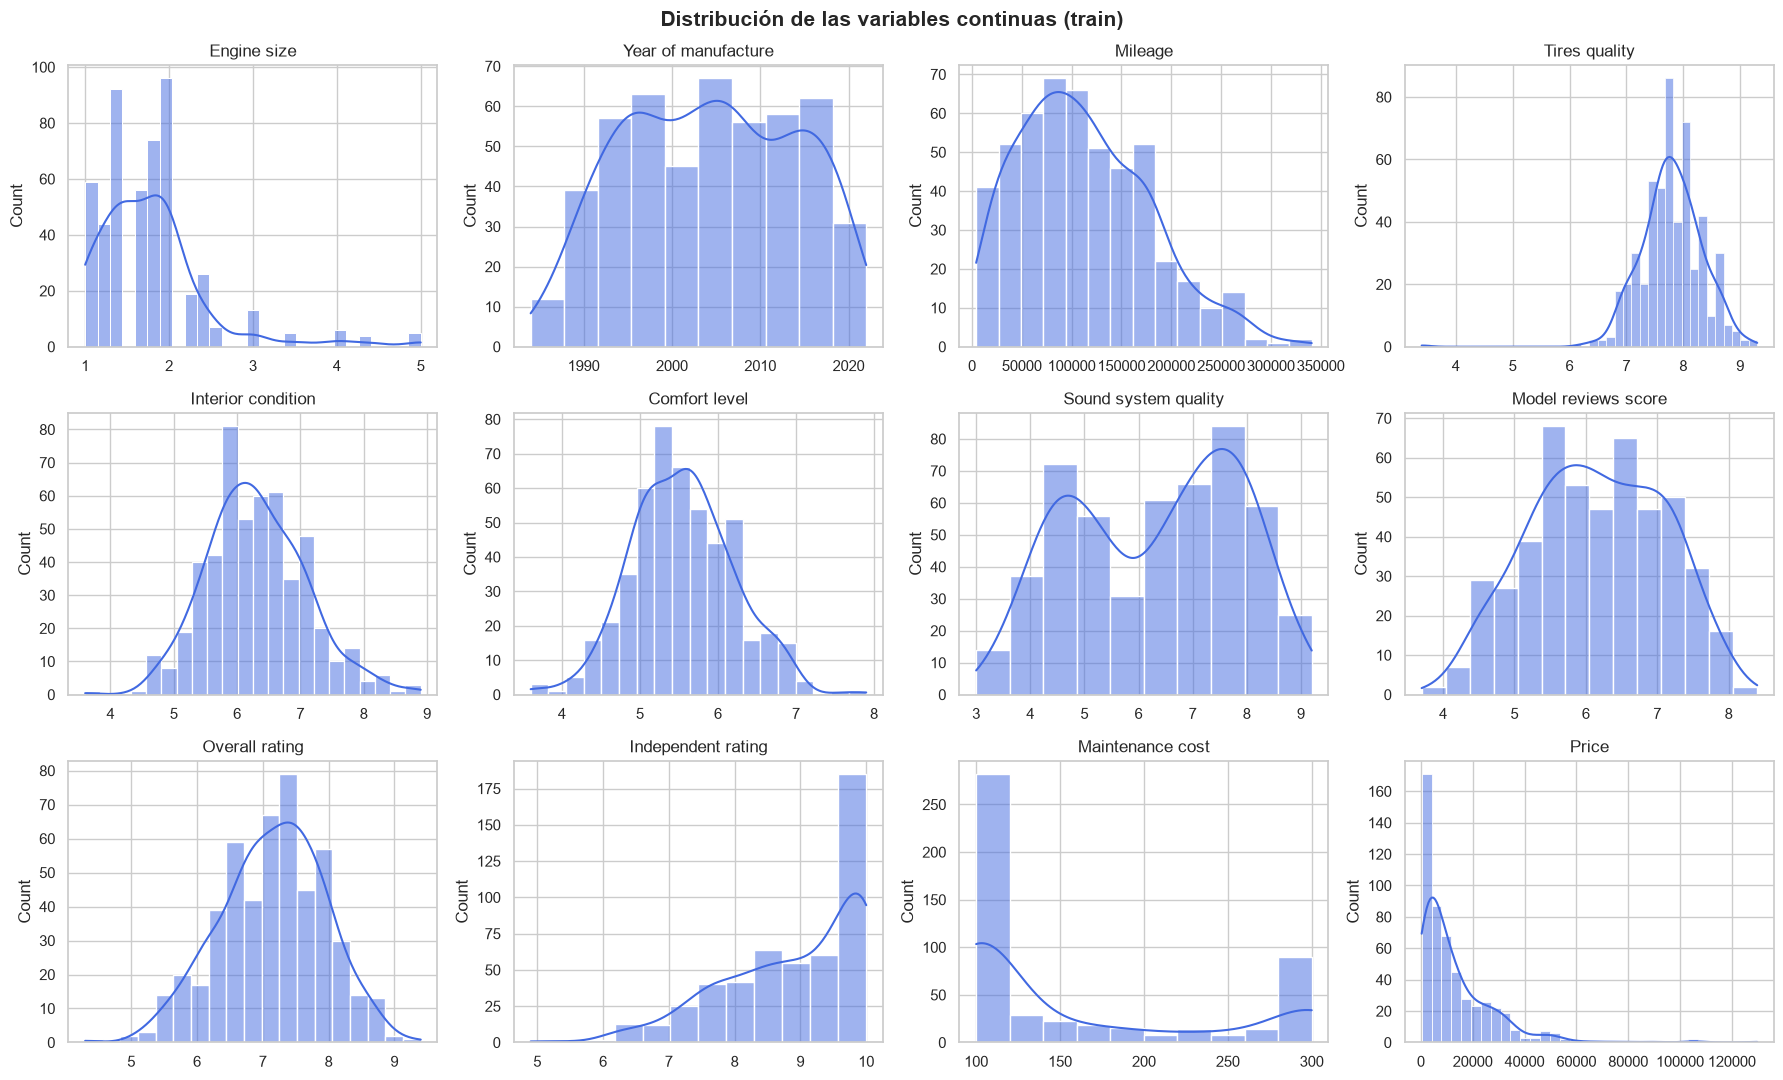

In [11]:
cont = ["Engine size", "Year of manufacture", "Mileage", "Tires quality", "Interior condition", "Comfort level", "Sound system quality", "Model reviews score", "Overall rating", "Independent rating", "Maintenance cost"]

train_eda = X_train.copy()
train_eda["Price"] = Y_train

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, var in zip(axes.flatten(), cont + ["Price"]):
    sns.histplot(train_eda[var].dropna(), kde=True, ax=ax, color="royalblue")
    ax.set_title(var)
    ax.set_xlabel("")
plt.suptitle("Distribución de las variables continuas (train)", fontweight="bold", fontsize=15)
plt.tight_layout()
plt.show()

**Observaciones:**
- **`Price`** tiene una asimetría muy fuerte a la derecha: la mayoría de coches valen menos de 20.000 €, pero hay unos pocos por encima de 100.000 €
- **`Mileage`** también es asimétrica a la derecha
- **`Year of manufacture`** es bastante uniforme entre 1990 y 2020
- **`Engine size`** es discreta (1.0, 1.2, 1.4... litros) con una cola larga de motores grandes (BMW M5, Porsche)
- Las valoraciones `Tires quality`, `Interior condition`, `Comfort level`, `Model reviews score` y `Overall rating` tienen forma de campana
- **`Sound system quality`** es bimodal (picos en 4.5 y 7.5): parece depender del tipo de coche o de la marca
- **`Independent rating`** está acumulada en 10
- **`Maintenance cost`** está acotada entre 100 y 300, con muchos coches justo en los extremos

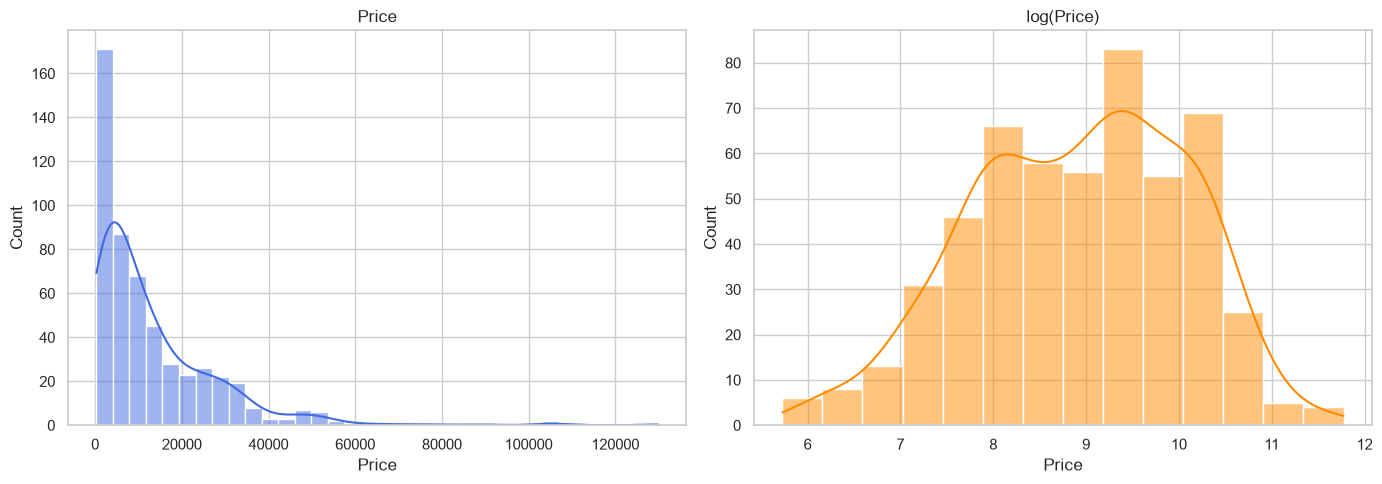

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(train_eda["Price"], kde=True, ax=axes[0], color="royalblue")
axes[0].set_title("Price")
sns.histplot(np.log(train_eda["Price"]), kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("log(Price)")
plt.tight_layout()
plt.show()

Al aplicar el logaritmo, el precio pasa de una distribución muy asimétrica a una forma mucho más simétrica y acampanada. Se acerca a una **log-normal** (no de manera exacta): el precio se forma multiplicando factores (marca\*antigüedad\*km etc...), no sumándolos. Se aprecian dos ligeros picos (8 y 9.5), que corresponden a la mezcla de gamas, modelos baratos y gama alta. Usaré esta transformación en el apartado b).

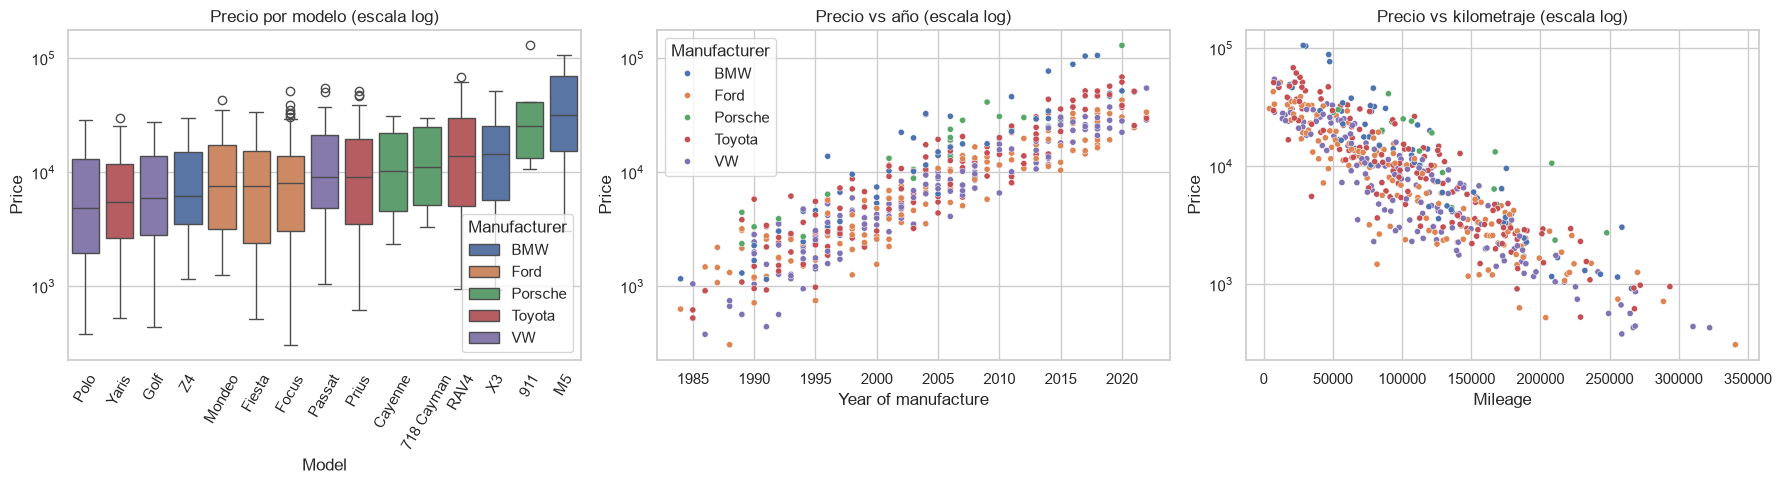

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
orden = train_eda.groupby("Model", observed=True)["Price"].median().sort_values().index
sns.boxplot(data=train_eda, x="Model", y="Price", order=orden, hue="Manufacturer", dodge=False, ax=axes[0])
axes[0].set_yscale("log")
axes[0].tick_params(axis="x", rotation=60)
axes[0].set_title("Precio por modelo (escala log)")
sns.scatterplot(data=train_eda, x="Year of manufacture", y="Price", hue="Manufacturer", ax=axes[1], s=20)
axes[1].set_yscale("log")
axes[1].set_title("Precio vs año (escala log)")
sns.scatterplot(data=train_eda, x="Mileage", y="Price", hue="Manufacturer", ax=axes[2], s=20, legend=False)
axes[2].set_yscale("log")
axes[2].set_title("Precio vs kilometraje (escala log)")
plt.tight_layout()
plt.show()

In [14]:
medianas = train_eda.groupby("Model", observed=True)["Price"].median().sort_values()
display(medianas)
print(f"911 / Polo: {medianas["911"] / medianas["Polo"]:.1f} veces")
print(f"M5  / Polo: {medianas["M5"]  / medianas["Polo"]:.1f} veces")

Model
Polo           4874.0
Yaris          5511.0
Golf           6006.0
Z4             6232.0
Mondeo         7577.0
Fiesta         7599.5
Focus          8039.5
Passat         9085.0
Prius          9136.5
Cayenne       10188.0
718 Cayman    11167.5
RAV4          13851.5
X3            14590.0
911           25261.0
M5            31584.5
Name: Price, dtype: float64

911 / Polo: 5.2 veces
M5  / Polo: 6.5 veces


- **Precio por modelo:** hay diferencias claras entre modelos (el M5 y el 911 cuestan de mediana unas 6 veces más que un Polo), pero dentro de cada modelo la dispersión es enorme (dos órdenes de magnitud). Por lo tanto, el modelo concreto no basta: el estado del coche es decisivo.
- **Precio vs año:** en escala logarítmica la relación es **casi una recta**. Esto quiere decir que el coche pierde aproximadamente el mismo porcentaje de valor cada año. En escala original esta relación sería una curva exponencial, que una regresión lineal no puede capturar.
- **Precio vs kilometraje:** también es aproximadamente lineal en escala logarítmica y decreciente.

Las marcas se separan verticalmente (BMW y Porsche por arriba, Ford y VW por debajo) con una pendiente parecida.

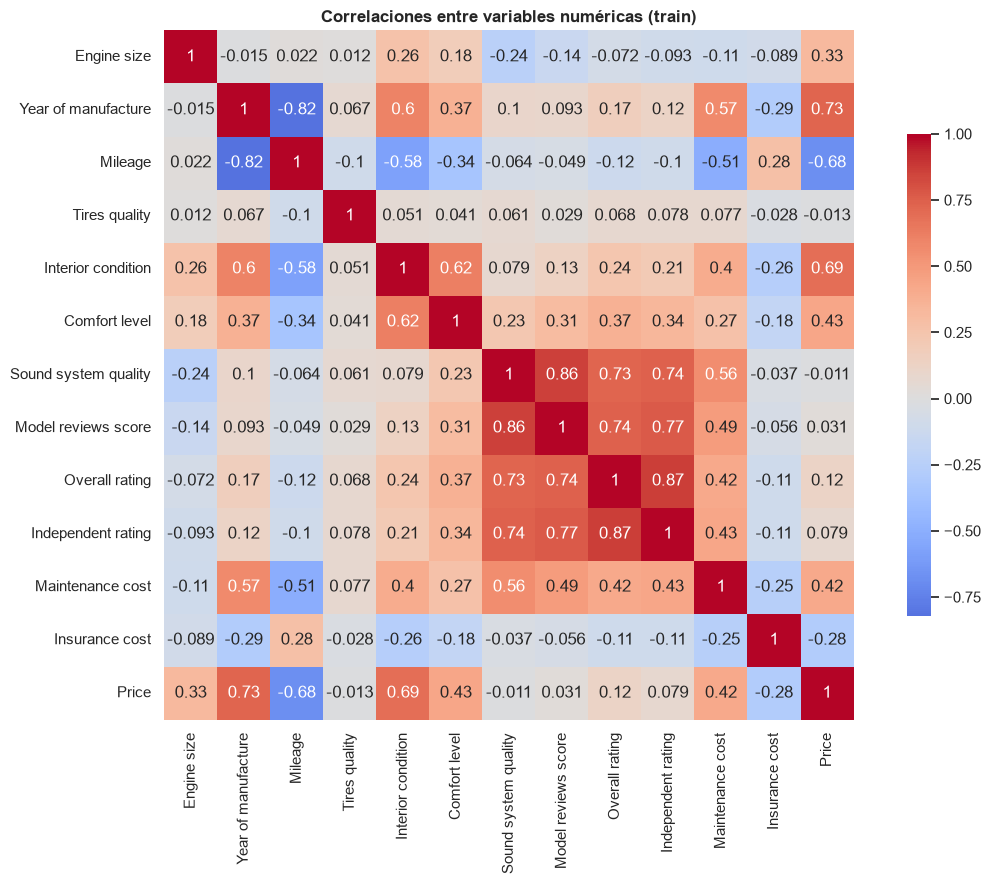

In [15]:
plt.figure(figsize=(12, 9))
corr = train_eda[cont + ["Insurance cost", "Price"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.7})
plt.title("Correlaciones entre variables numéricas (train)", fontweight="bold")
plt.tight_layout()
plt.show()

- Las variables más correlacionadas con el precio son **`Year of manufacture` (0.73)**, **`Interior condition` (0.69)** y **`Mileage` (-0.68)**
- `Year` y `Mileage` están muy correlacionadas entre sí (-0.82): los coches más viejos tienen más kilómetros. `Interior condition` también depende de la antigüedad (0.60 con el año y -0.58 con el kilometraje). Su correlación con el precio puede ser en gran parte **indirecta**, a través de la antigüedad.
- Hay un bloque de valoraciones muy correlacionadas entre sí (`Sound system quality`, `Model reviews score`, `Overall rating`, `Independent rating`, entre 0.73 y 0.87) que, sin embargo, **casi no tiene relación con el precio** (< 0.12). Este bloque es redundante y, previsiblemente, poco útil para predecir
- `Tires quality` no está correlacionada con nada.

Esta colinealidad podría afectar a la interpretación de los pesos de la regresión lineal. Lo comprobaré en el apartado c) comparando con Ridge y LASSO.

### Outliers

Las valoraciones (`Tires quality`, `Interior condition`, `Comfort level`, `Model reviews score`, `Overall rating`) tienen forma aproximadamente normal (lo comprobamos con el Q-Q plot de cada una). Para tratar los outliers utilizaré la regla de las **3 desviaciones típicas**. Debido a que la regresión lineal es sensible a outliers los eliminaré con esta regla.

Solo filtraré las filas de train, el test debe representar datos reales tal cual nos llegarían al modelo.

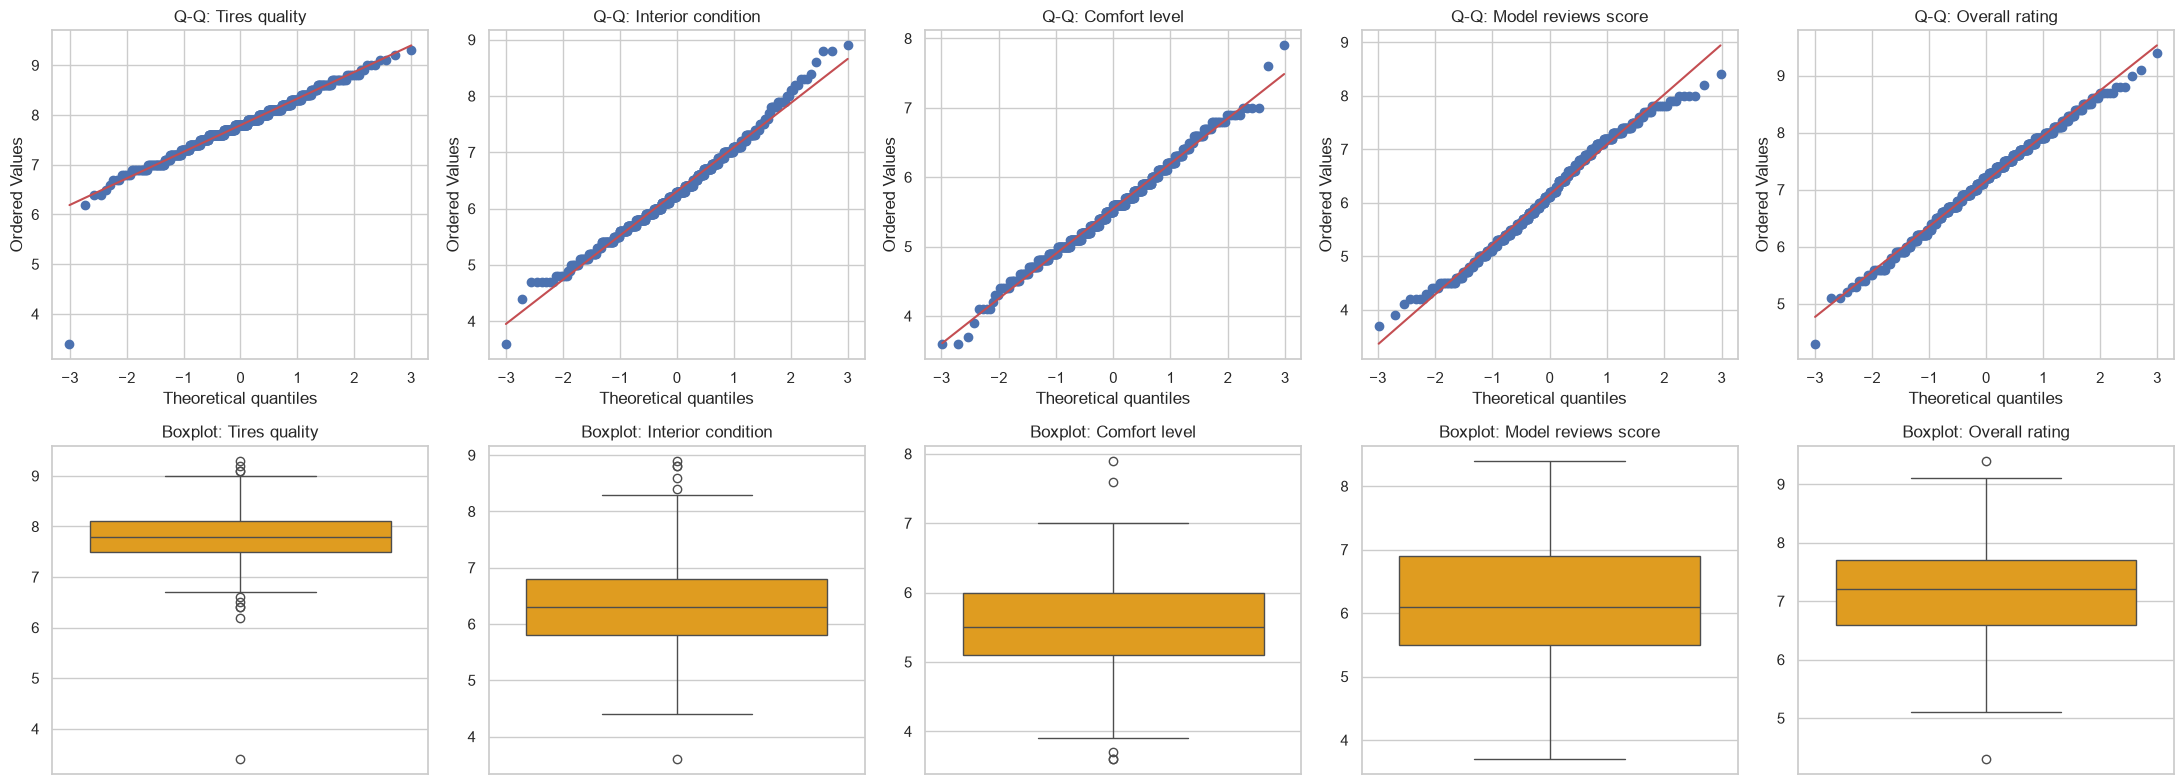

In [16]:
variables_normales = ["Tires quality", "Interior condition", "Comfort level", "Model reviews score", "Overall rating"]

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for i, var in enumerate(variables_normales):
    stats.probplot(train_eda[var].dropna(), dist="norm", plot=axes[0, i])
    axes[0, i].set_title(f"Q-Q: {var}")
    sns.boxplot(y=train_eda[var].dropna(), ax=axes[1, i], color="orange")
    axes[1, i].set_title(f"Boxplot: {var}")
    axes[1, i].set_ylabel("")
plt.tight_layout()
plt.show()

In [17]:
n_antes = len(train_eda)
for col in variables_normales:
    media, std = train_eda[col].mean(), train_eda[col].std()
    dentro = train_eda[col].between(media - 3*std, media + 3*std)
    train_eda = train_eda[train_eda[col].isna() | dentro]   # los NaN se conservan (los imputaré luego)
X_train = X_train.loc[train_eda.index]
Y_train = Y_train.loc[train_eda.index]
print(f"Filas eliminadas como outliers: {n_antes - len(train_eda)}  ->  train final: {len(X_train)} coches")

Filas eliminadas como outliers: 6  ->  train final: 519 coches


Los Q-Q plots confirman que las cinco valoraciones siguen bastante bien la diagonal (normalidad razonable), salvo algunos puntos aislados en las colas, como un `Tires quality` de 3.5 aproximadamente o un `Interior condition` de 3.6. La regla de $3\sigma$ elimina solo **6 coches** , así que la limpieza es conservadora y no perdemos ninguna información que sea relevante.

## Codificación, estandarización e imputación con KNN

El orden que seguiré:

1. Codificar las categóricas con la función `codificar` que he programado antes, la función `align` me garantiza que train y test tengan exactamente las mismas columnas.
2. Estandarizar las continuas con `StandardScaler` antes de imputar, `KNNImputer` busca vecinos por distancia euclídea, y sin escalar algunas variables dominarían a todas las demás variables. `StandardScaler` ignora los NaN al calcular media y desviación, así que se puede aplicar antes de imputar.
3. **Imputar** con `KNNImputer(n_neighbors=5)` (valor por defecto): cada NaN se sustituye por la media de los 5 coches más parecidos, lo que es más realista que la media global.
4. `Insurance cost` es binaria, así que redondeamos su valor imputado a 0 o 1.

La variable objetivo no participa en la imputación ya que sería fuga de información (para un coche nuevo no conoceríamos su precio).

In [18]:
X_train = codificar(X_train)
X_test = codificar(X_test)
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0.0)

scaler = StandardScaler().set_output(transform="pandas")
X_train[cont] = scaler.fit_transform(X_train[cont])
X_test[cont] = scaler.transform(X_test[cont])

imputer = KNNImputer().set_output(transform="pandas")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

X_train["Insurance cost"] = X_train["Insurance cost"].round()
X_test["Insurance cost"] = X_test["Insurance cost"].round()

print(f"NaN restantes -> train: {X_train.isna().sum().sum()}, test: {X_test.isna().sum().sum()}")
print(f"Columnas ({X_train.shape[1]}): {list(X_train.columns)}")

NaN restantes -> train: 0, test: 0
Columnas (28): ['Engine size', 'Year of manufacture', 'Mileage', 'Tires quality', 'Interior condition', 'Comfort level', 'Sound system quality', 'Model reviews score', 'Overall rating', 'Independent rating', 'Insurance cost', 'Maintenance cost', 'Model_911', 'Model_Cayenne', 'Model_Fiesta', 'Model_Focus', 'Model_Golf', 'Model_M5', 'Model_Mondeo', 'Model_Passat', 'Model_Polo', 'Model_Prius', 'Model_RAV4', 'Model_X3', 'Model_Yaris', 'Model_Z4', 'Fuel type_Hybrid', 'Fuel type_Petrol']


## PCA

Aplicamos PCA sobre el conjunto preprocesado (continuas estandarizadas + dummies). Las dummies no se estandarizan, son binarias y tienen varianza pequeña, por lo que el PCA estará dominado por las continuas, que es lo que queremos para ver el "estado" del coche.

Varianza explicada PC0: 34.11%, PC1: 19.80% (juntas 53.91%)
Componentes necesarias para el 90% de la varianza: 10 de 28


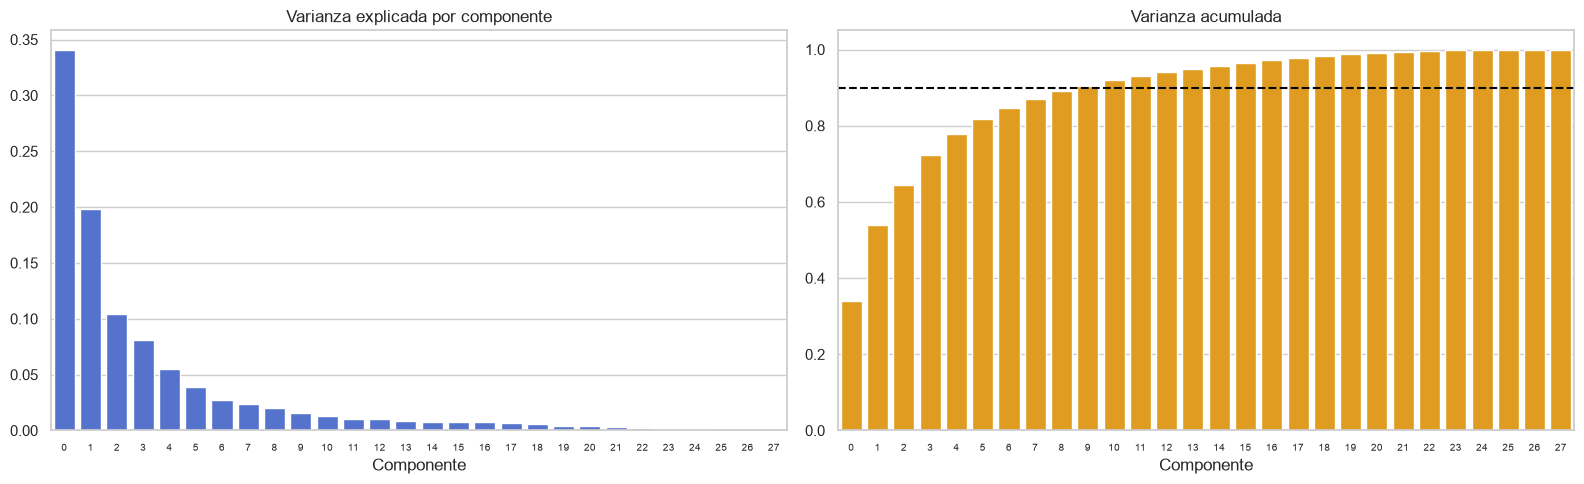

In [19]:
pca = PCA().set_output(transform="pandas")
componentes = pca.fit_transform(X_train)
varianza = pca.explained_variance_ratio_
varianza_acumulada = varianza.cumsum()
n90 = np.argmax(varianza_acumulada >= 0.9) + 1
print(f"Varianza explicada PC0: {varianza[0]:.2%}, PC1: {varianza[1]:.2%} (juntas {varianza_acumulada[1]:.2%})")
print(f"Componentes necesarias para el 90% de la varianza: {n90} de {pca.n_components_}")

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=np.arange(pca.n_components_), y=varianza, ax=ax[0], color="royalblue")
ax[0].set_title("Varianza explicada por componente")
sns.barplot(x=np.arange(pca.n_components_), y=varianza_acumulada, ax=ax[1], color="orange")
ax[1].axhline(0.9, linestyle="--", color="black")
ax[1].set_title("Varianza acumulada")
for a in ax:
    a.set_xlabel("Componente")
    a.tick_params(axis="x", labelsize=7)
plt.tight_layout()
plt.show()

Las dos primeras componentes explican el 53.9% de la varianza (PC0 34.1%, PC1 19.8%). Hacen falta 10 componentes para llegar al 90%. A partir de la 20 la varianza es prácticamente nula  (son las dummy que tienen muy poca varianza).

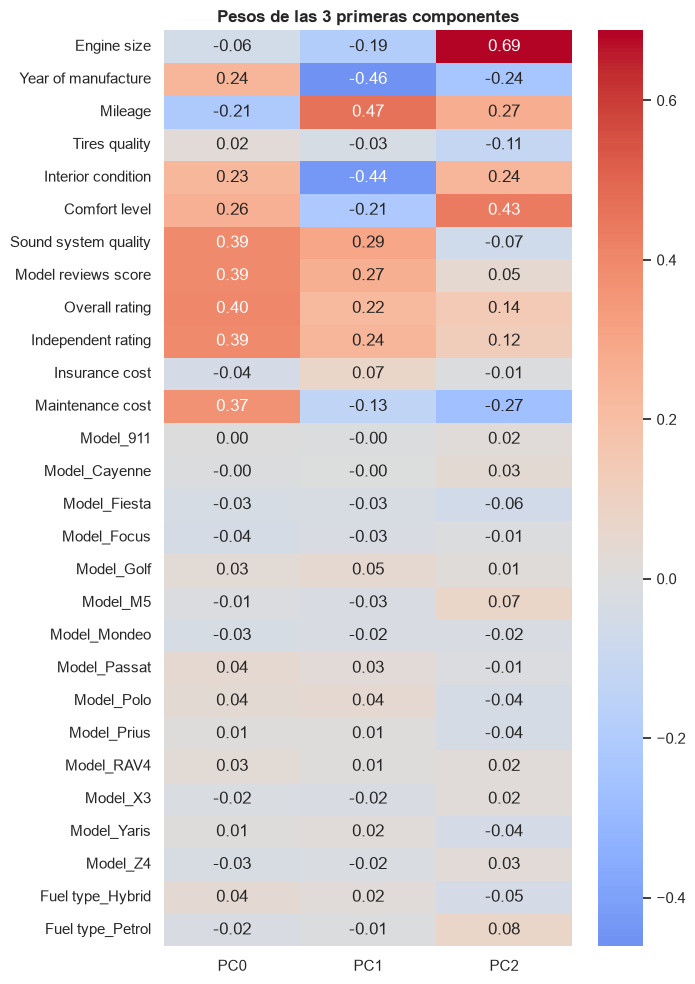

In [20]:
cargas = pd.DataFrame(pca.components_[:3].T, index=X_train.columns, columns=["PC0", "PC1", "PC2"])
plt.figure(figsize=(7, 10))
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Pesos de las 3 primeras componentes", fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretación de las componentes:**
- **PC0: "valoraciones del coche":** pesos positivos y casi iguales en `Sound system quality`, `Model reviews score`, `Overall rating` e `Independent rating` (~0.40), y también en `Maintenance cost` (0.37). Es el bloque de variables correlacionadas que vimos en el mapa de calor.
- **PC1: "antigüedad y desgaste":** `Mileage` (+0.47) frente a `Year of manufacture` (-0.46) e `Interior condition` (-0.44). Un PC1 alto corresponde a un coche viejo, con muchos kilómetros y el interior gastado.
- **PC2: "motor y confort":** dominada por `Engine size` (0.69) y `Comfort level` (0.43).

Las dummy de modelo apenas pesan en las primeras componentes porque tienen poca varianza.

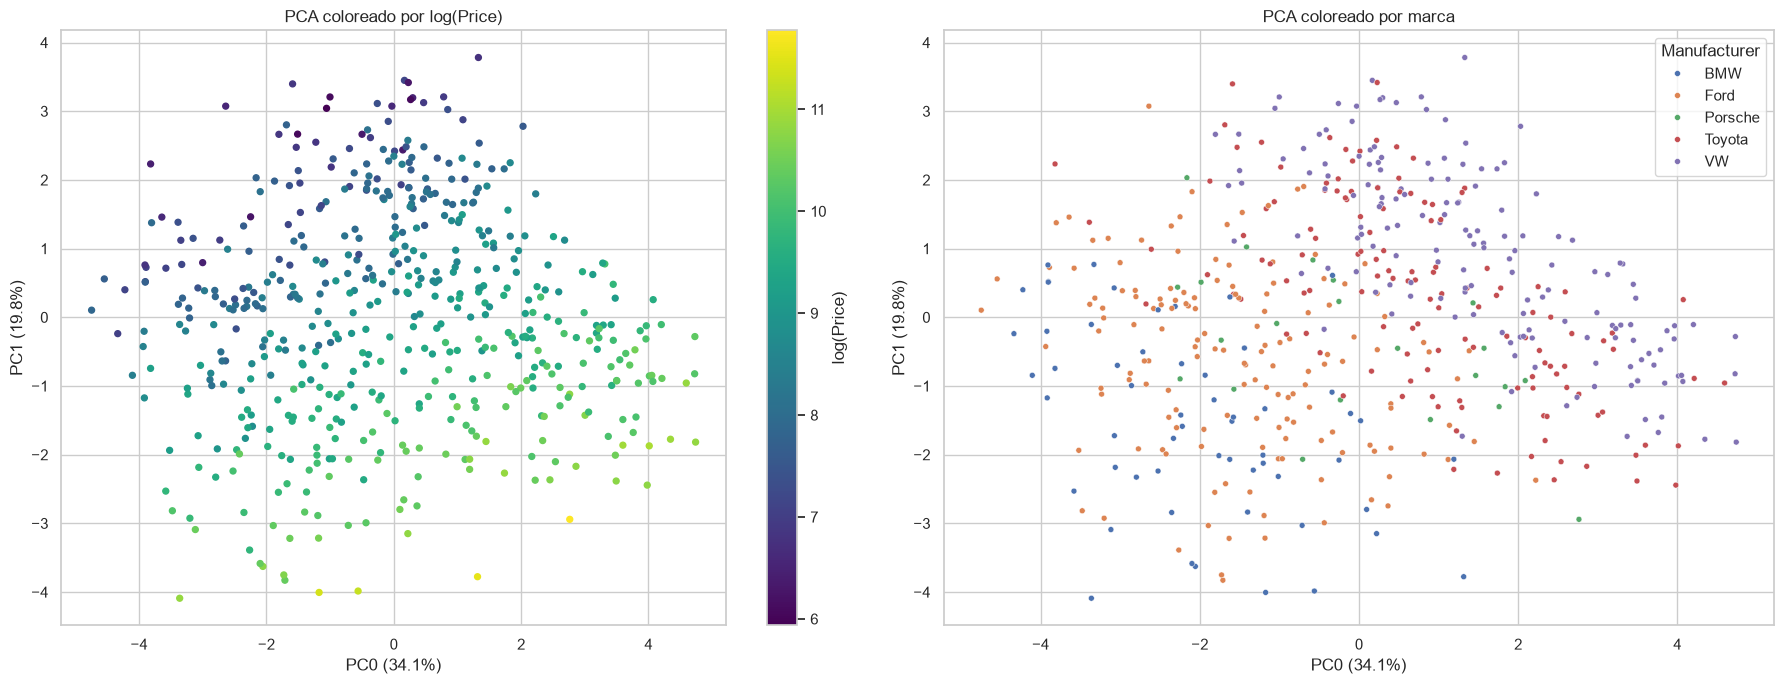

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sc = axes[0].scatter(componentes["pca0"], componentes["pca1"], c=np.log(Y_train), cmap="viridis", s=18)
plt.colorbar(sc, ax=axes[0], label="log(Price)")
axes[0].set_title("PCA coloreado por log(Price)")
marcas = df.loc[X_train.index, "Manufacturer"]   # solo para colorear el gráfico (no entra en el modelo)
sns.scatterplot(x=componentes["pca0"], y=componentes["pca1"], hue=marcas, ax=axes[1], s=18)
axes[1].set_title("PCA coloreado por marca")
for a in axes:
    a.set_xlabel(f"PC0 ({varianza[0]:.1%})")
    a.set_ylabel(f"PC1 ({varianza[1]:.1%})")
plt.tight_layout()
plt.show()

**Precio sobre las dos primeras componentes:**
- El precio varía sobre todo a lo largo de **PC1**: los coches caros (amarillo) están abajo (nuevos, pocos km) y los baratos (morado) arriba (viejos, muchos km). Es un gradiente casi perfecto, lo que confirma que **antigüedad y kilometraje son lo que más determina el precio**.
- A lo largo de **PC0** (valoraciones) el color casi no cambia, las valoraciones no explican el precio, coherente con su baja correlación.
- Coloreando por marca (solo para visualizar) se ve que PC0 separa las marcas, Ford y BMW a la izquierda (valoraciones bajas) y VW y Toyota a la derecha. Las valoraciones dependen más de la marca que del valor del coche.
- No aparecen grupos separados, el precio cambia de forma continua. La relación es casi lineal en `log(Price)`, lo que parece que un modelo lineal sobre el logaritmo del precio funcionará bien.

# Apartado b) Regresión lineal

## Transformación de las variables

Las variables explicativas ya están transformadas de forma consistente en train y test. Falta decidir qué hacer con la variable objetivo. Empezaré ajustando la regresión lineal sobre el precio original como modelo base, para ver si el resultado es razonable.

Definimos una función de evaluación que usaremos con todos los modelos. Si el modelo se entrena con `log(Price)`, deshace la transformación con `exp` para que todas las métricas estén en euros y sean comparables:
- **$R^2$**: proporción de la varianza del precio que explica el modelo (1 = perfecto)
- **RMSE**: error típico en euros, penaliza mucho los errores grandes
- **MAE**: error absoluto medio en euros
- **MAPE**: error relativo medio en %

In [22]:
def evaluar(modelo, Xtr, Xte, log=False):
    pred_train, pred_test = modelo.predict(Xtr), modelo.predict(Xte)
    if log:
        pred_train, pred_test = np.exp(pred_train), np.exp(pred_test)
    return {
        "R2 train": r2_score(Y_train, pred_train),
        "R2 test": r2_score(Y_test, pred_test),
        "RMSE test": np.sqrt(mean_squared_error(Y_test, pred_test)),
        "MAE test": mean_absolute_error(Y_test, pred_test),
        "MAPE test (%)": mean_absolute_percentage_error(Y_test, pred_test) * 100,
    }

lr_raw = LinearRegression().fit(X_train, Y_train)
cv_raw = cross_val_score(LinearRegression(), X_train, Y_train, cv=5, scoring="r2").mean()
print(f"R2 medio en validación cruzada (5 folds): {cv_raw:.3f}")
print(f"Predicciones negativas en test: {(lr_raw.predict(X_test) < 0).sum()} de {len(X_test)}")
pd.Series(evaluar(lr_raw, X_train, X_test)).round(3).to_frame("Lineal (Price)")

R2 medio en validación cruzada (5 folds): 0.694
Predicciones negativas en test: 40 de 225


,Lineal (Price)
R2 train,0.748
R2 test,0.726
RMSE test,8405.926
MAE test,5120.503
MAPE test (%),304.797


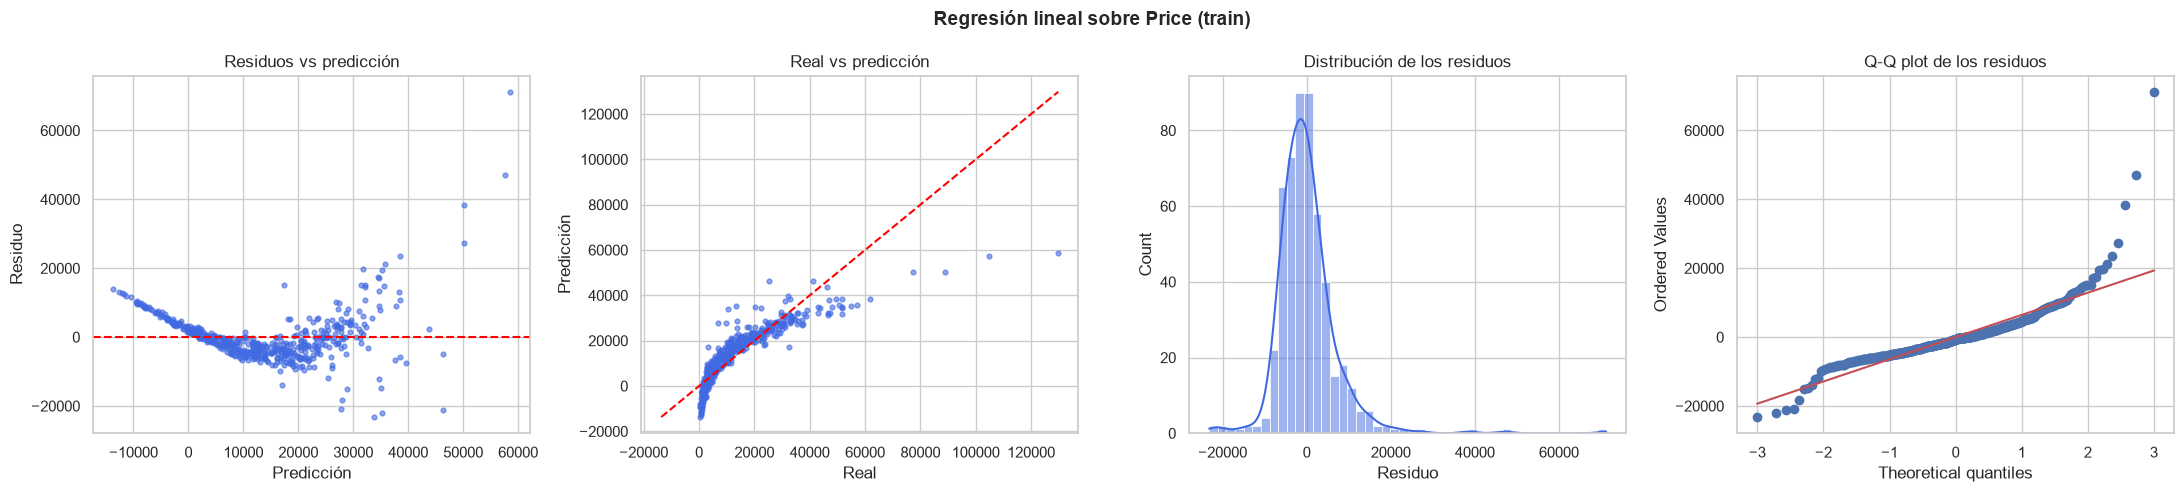

In [23]:
def graficar_residuos(y_real, y_pred, titulo, color="royalblue"):
    residuos = y_real - y_pred
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    axes[0].scatter(y_pred, residuos, s=12, alpha=0.6, color=color)
    axes[0].axhline(0, color="red", linestyle="--")
    axes[0].set_xlabel("Predicción")
    axes[0].set_ylabel("Residuo")
    axes[0].set_title("Residuos vs predicción")
    axes[1].scatter(y_real, y_pred, s=12, alpha=0.6, color=color)
    lim = [min(y_real.min(), y_pred.min()), max(y_real.max(), y_pred.max())]
    axes[1].plot(lim, lim, color="red", linestyle="--")
    axes[1].set_xlabel("Real")
    axes[1].set_ylabel("Predicción")
    axes[1].set_title("Real vs predicción")
    sns.histplot(residuos, kde=True, ax=axes[2], color=color)
    axes[2].set_title("Distribución de los residuos")
    axes[2].set_xlabel("Residuo")
    stats.probplot(residuos, dist="norm", plot=axes[3])
    axes[3].set_title("Q-Q plot de los residuos")
    fig.suptitle(titulo, fontweight="bold", fontsize=14)
    plt.tight_layout()
    plt.show()

graficar_residuos(Y_train, lr_raw.predict(X_train), "Regresión lineal sobre Price (train)")

Se observa que el modelo sobre el precio original no es bueno. $R^2$ de 0.73 en test, MAE de unos 5.100 €, y 40 de los 225 coches de test (18%) tienen precio predicho negativo, lo que no tiene sentido. El MAPE del 305% sale de los coches baratos, a los que se predice un precio muy alejado.

Los residuos muestran un patrón muy marcado en forma de U (parábola):
- Para predicciones bajas (incluidas las negativas) los residuos son positivos, el modelo **infravalora** los coches baratos
- En la zona media los residuos son negativos **sobrevalora**
- Para predicciones altas vuelven a ser positivos y además mucho más dispersos
- En "Real vs predicción" los puntos forman una curva, no una recta
- Los residuos no son normales, el Q-Q plot tiene una cola derecha muy pesada

Esto incumple las hipótesis de la regresión lineal. La relación entre las variables y el precio **no es lineal**, es exponencial o multiplicativa, como vimos en la exploración anteriormente.

## Transformación logarítmica del precio

El precio es estrictamente positivo, muy asimétrico, y los efectos parecen multiplicativos (un coche pierde un porcentaje de su valor cada año, no una cantidad fija). Todo ello apunta a modelar $\log(\text{Price})$.
Las predicciones serán siempre positivas, la distribución se vuelve más simétrica, y cada peso se interpreta como un efecto porcentual.

In [24]:
Y_train_log = np.log(Y_train)
Y_test_log = np.log(Y_test)

lr_log = LinearRegression().fit(X_train, Y_train_log)
cv_log = cross_val_score(LinearRegression(), X_train, Y_train_log, cv=5, scoring="r2").mean()
print(f"R2 medio en validación cruzada (escala log): {cv_log:.3f}")
print(f"R2 en test en escala log: {r2_score(Y_test_log, lr_log.predict(X_test)):.3f}\n")
metricas_b = pd.DataFrame({"Lineal (Price)": evaluar(lr_raw, X_train, X_test), "Lineal (log Price)": evaluar(lr_log, X_train, X_test, log=True)})
metricas_b.round(3)

R2 medio en validación cruzada (escala log): 0.990
R2 en test en escala log: 0.991



,Lineal (Price),Lineal (log Price)
R2 train,0.748,0.970
R2 test,0.726,0.987
RMSE test,8405.926,1828.848
MAE test,5120.503,877.954
MAPE test (%),304.797,7.295


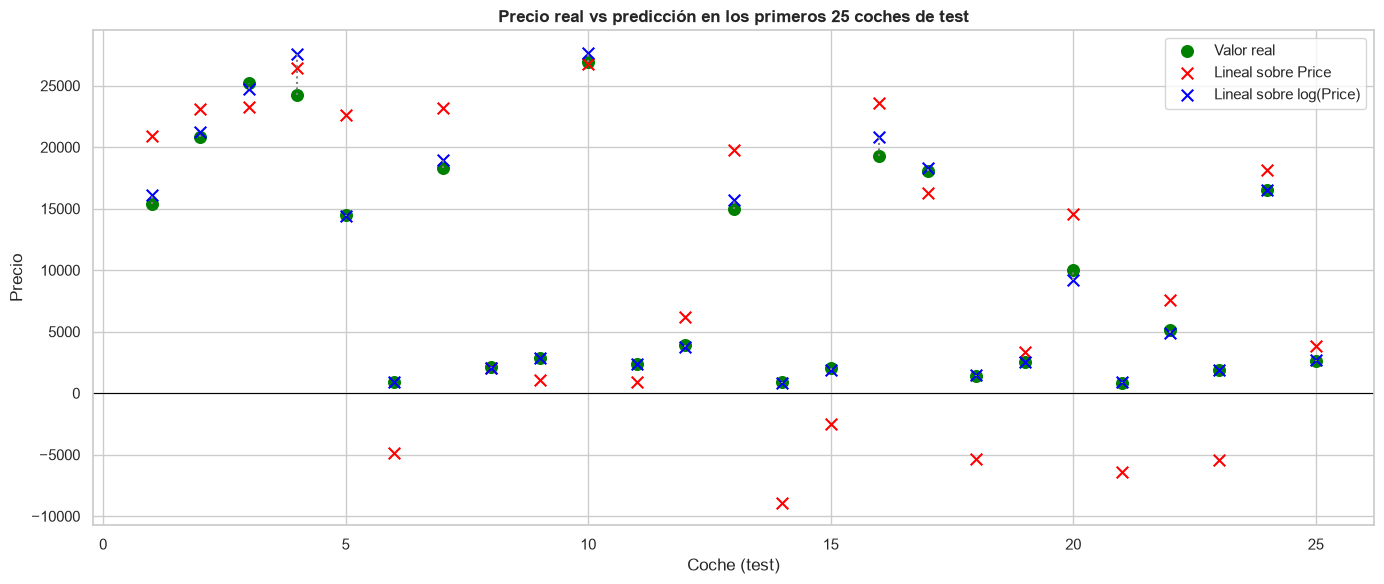

In [25]:
n = 25
pred_raw = lr_raw.predict(X_test)[:n]
pred_log = np.exp(lr_log.predict(X_test))[:n]
real = Y_test.values[:n]
x = np.arange(1, n + 1)

plt.figure(figsize=(14, 6))
plt.vlines(x, np.minimum(pred_log, real), np.maximum(pred_log, real), color="gray", linestyle=":")
plt.scatter(x, real, s=70, color="green", label="Valor real")
plt.scatter(x, pred_raw, s=70, marker="x", color="red", label="Lineal sobre Price")
plt.scatter(x, pred_log, s=70, marker="x", color="blue", label="Lineal sobre log(Price)")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Coche (test)")
plt.ylabel("Precio")
plt.title(f"Precio real vs predicción en los primeros {n} coches de test", fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()

La transformación logarítmica mejora el modelo de forma drástica, con las métricas medidas en euros en ambos casos:

| | Lineal (Price) | Lineal (log Price) |
|---|---|---|
| $R^2$ test | 0.726 |0.987 |
| MAE test | 5.121 € | 878 € |
| MAPE test | 305% | 7.3% |

El $R^2$ medio en validación cruzada (0.990 en escala log) es parecido al de test, así que el modelo generaliza bien y no está sobreajustado. Que el $R^2$ de test sea algo mayor que el de train (0.970) se explica porque train contiene los coches más extremos (el más caro, de 131.000 €, y los outliers de residuo). En la gráfica, las predicciones del modelo logarítmico (azul) caen casi encima del valor real, mientras que el modelo sin transformar (rojo) da valores negativos y errores de miles de euros.
Es suficientemente bueno debido a que un error típico de aproximadamente 7% sobre el precio es un resultado muy bueno para tasar coches usados. Aun así hay algunos coches con errores grandes (ver los residuos más abajo).

## Pesos del modelo lineal

Analizamos los pesos del modelo con `log(Price)`, que es el bueno. Los pesos del modelo sobre `Price` no los interpreto, ya que ese modelo incumple las hipótesis de la regresión lineal (residuos en forma de U, predicciones negativas), por lo que sus pesos no reflejan el efecto real de cada variable. 

Intercepto: 9.254  -->  precio base 10,445 €


,Peso,Efecto en precio (%)
Model_Fiesta,-0.716,-51.148
Model_Polo,-0.677,-49.201
Mileage,-0.535,-41.449
Model_Yaris,-0.534,-41.372
Model_Golf,-0.455,-36.584
Model_Mondeo,-0.270,-23.630
Model_Prius,-0.262,-23.080
Model_Focus,-0.237,-21.128
Model_Passat,-0.228,-20.366
Model_Z4,-0.166,-15.272


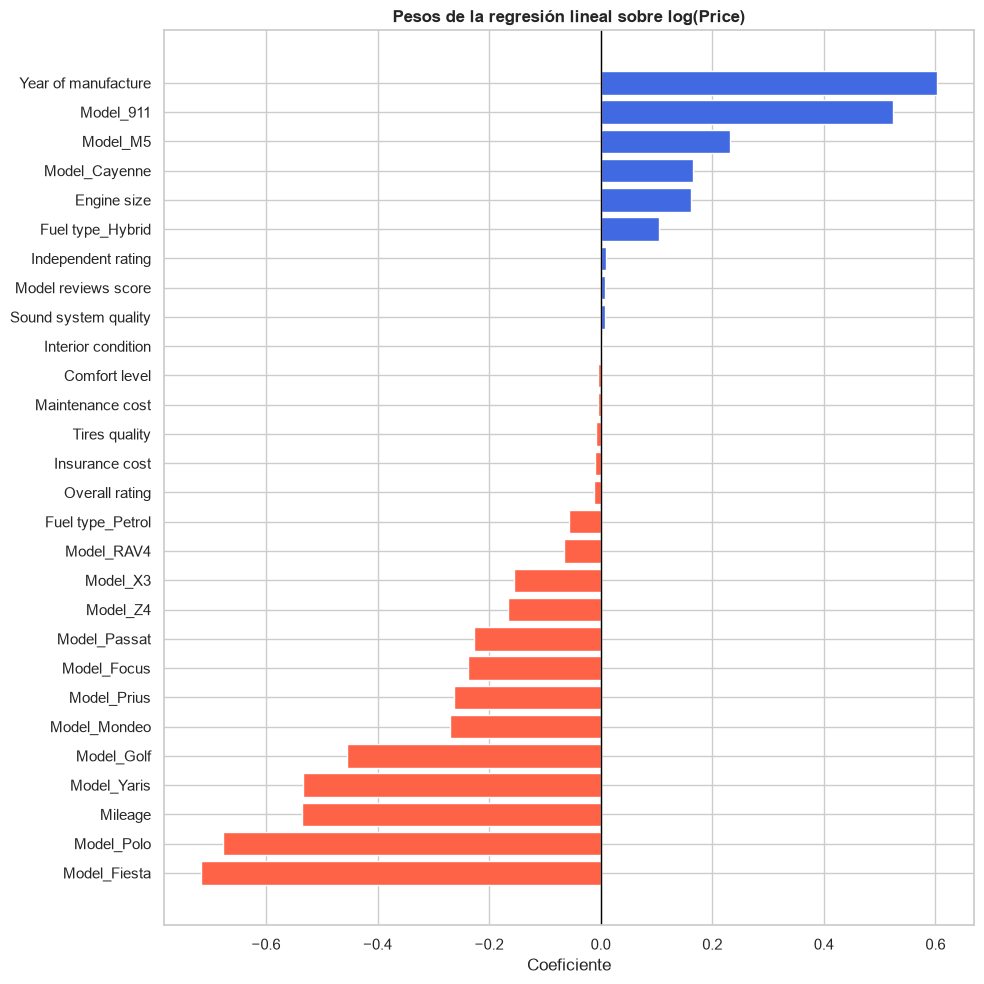

In [26]:
pesos_lr = pd.DataFrame({"Peso": lr_log.coef_, "Efecto en precio (%)": (np.exp(lr_log.coef_) - 1)*100},  index=X_train.columns).sort_values("Peso")
print(f"Intercepto: {lr_log.intercept_:.3f}  -->  precio base {np.exp(lr_log.intercept_):,.0f} €")
display(pesos_lr.round(3))
plt.figure(figsize=(10, 10))
colores = ["tomato" if p < 0 else "royalblue" for p in pesos_lr["Peso"]]
plt.barh(pesos_lr.index, pesos_lr["Peso"], color=colores)
plt.axvline(0, color="black", linewidth=1)
plt.title("Pesos de la regresión lineal sobre log(Price)", fontweight="bold")
plt.xlabel("Coeficiente")
plt.tight_layout()
plt.show()

Interpretación de los pesos:

Variables continuas (efecto de +1 desviación típica):
- **`Year of manufacture` (+0.60 -> +83%)** es la más importante. Una desviación típica son unos 10 años, así que esto equivale a unos **+6% de valor por cada año más nuevo**. Es decir, el coche se deprecia $\approx$ 6% al año
- **`Mileage` (-0.54 -> -41%)**: cada aproximadamente 68.000 km adicionales el precio baja un 41%. Aun corrigiendo por el año, el kilometraje tiene un efecto propio muy fuerte
- **`Engine size` (+0.16 -> +18%)**: los motores más grandes valen más
- **Las valoraciones (`Overall rating`, `Sound system quality`, `Model reviews score`, `Tires quality`, `Comfort level`, `Independent rating`) y `Interior condition` tienen pesos casi nulos (<=1%).** Aunque `Interior condition` tenía correlación 0.69 con el precio, una vez que el modelo conoce el año y los kilómetros ya no aporta nada: su correlación era indirecta
- `Insurance cost` y `Maintenance cost` tampoco aportan ($\approx$-1%)

Modelo (respecto al Porsche 718 Cayman, en igualdad de año, km, motor etc...):
- **Más caros:** `911` (+69%), `M5` (+26%) y `Cayenne` (+18%). Son los deportivos y SUV de gama alta
- **Parecidos:** `RAV4` (-6%)
- **Gama media:** `X3` (-14%), `Z4` (-15%), `Passat` (-20%), `Focus` (-21%), `Prius` (-23%) y `Mondeo` (-24%)
- **Más baratos:** `Golf` (-37%), `Yaris` (-41%), `Polo` (-49%) y `Fiesta` (-51%). Son los utilitarios

El orden de los modelos reproduce la gama de mercado, gama alta (Porsche, BMW) > SUV/berlinas > utilitarios. La **marca aparece de forma implícita**, todos los Porsche y BMW están arriba y Ford, VW y Toyota abajo. No hace falta `Manufacturer`.
Combustible: híbrido +11% y gasolina -5.5% respecto a diésel.
**Conclusión:** el precio se explica sobre todo por **antigüedad, kilometraje, modelo y motor**. Las valoraciones subjetivas del coche apenas influyen.

## Residuos del modelo con log(Price)

Los residuos se calculan en la escala en la que se ha ajustado el modelo (log), que es donde deben cumplirse las hipótesis de la regresión lineal (media 0, varianza constante, normalidad). Además, los representamos frente a las variables más importantes para detectar relaciones no lineales que el modelo no capture.

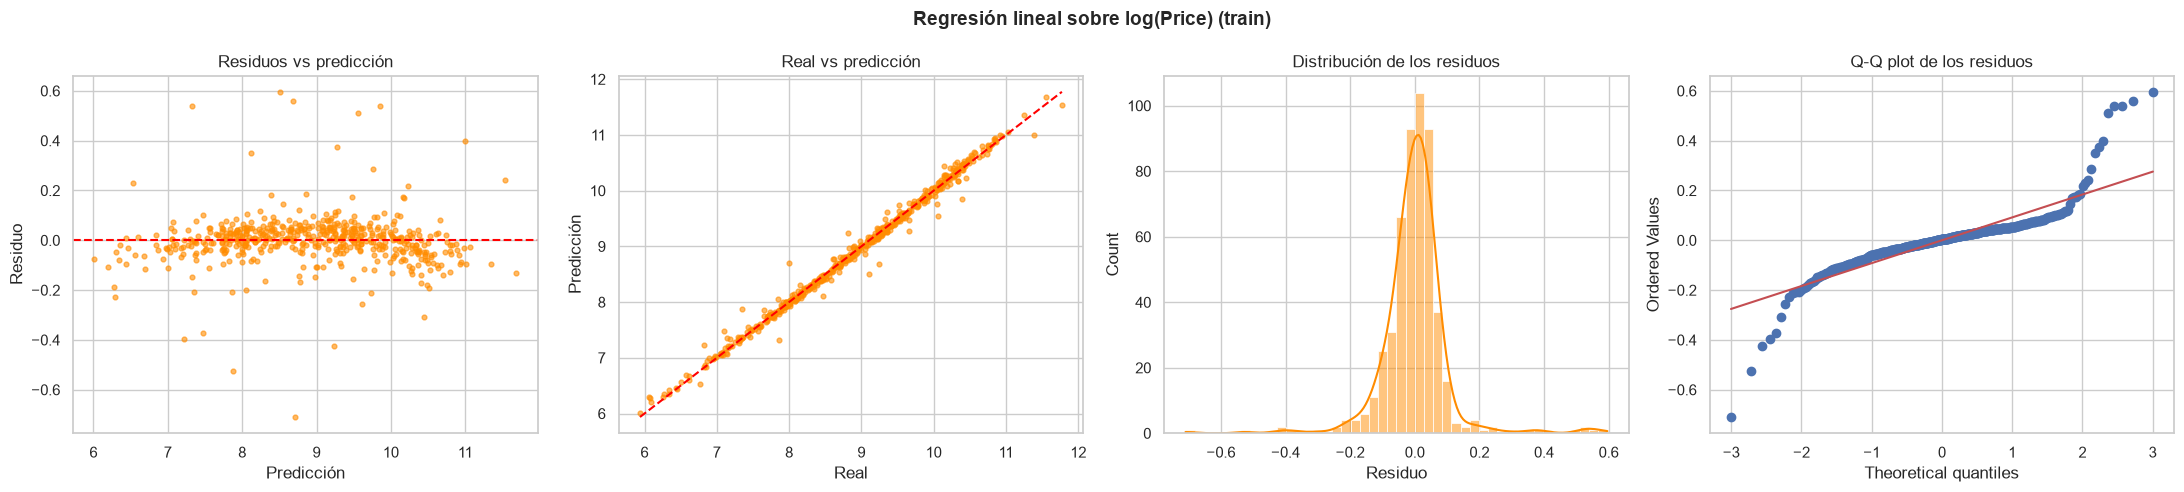

In [27]:
graficar_residuos(Y_train_log, lr_log.predict(X_train), "Regresión lineal sobre log(Price) (train)", color="darkorange")

Residuos del modelo logarítmico:
- **Residuos vs predicción:** nube centrada en 0 y de anchura constante. El patrón en U ha desaparecido y no hay heterocedasticidad
- **Real vs predicción:** los puntos están sobre la diagonal
- **Distribución:** muy concentrada y centrada en 0, pero el **Q-Q plot tiene forma de S, con colas pesadas**. Algunos coches cuyo precio no se explica con estas variables (ventas atípicas, posibles errores en los datos etc...)

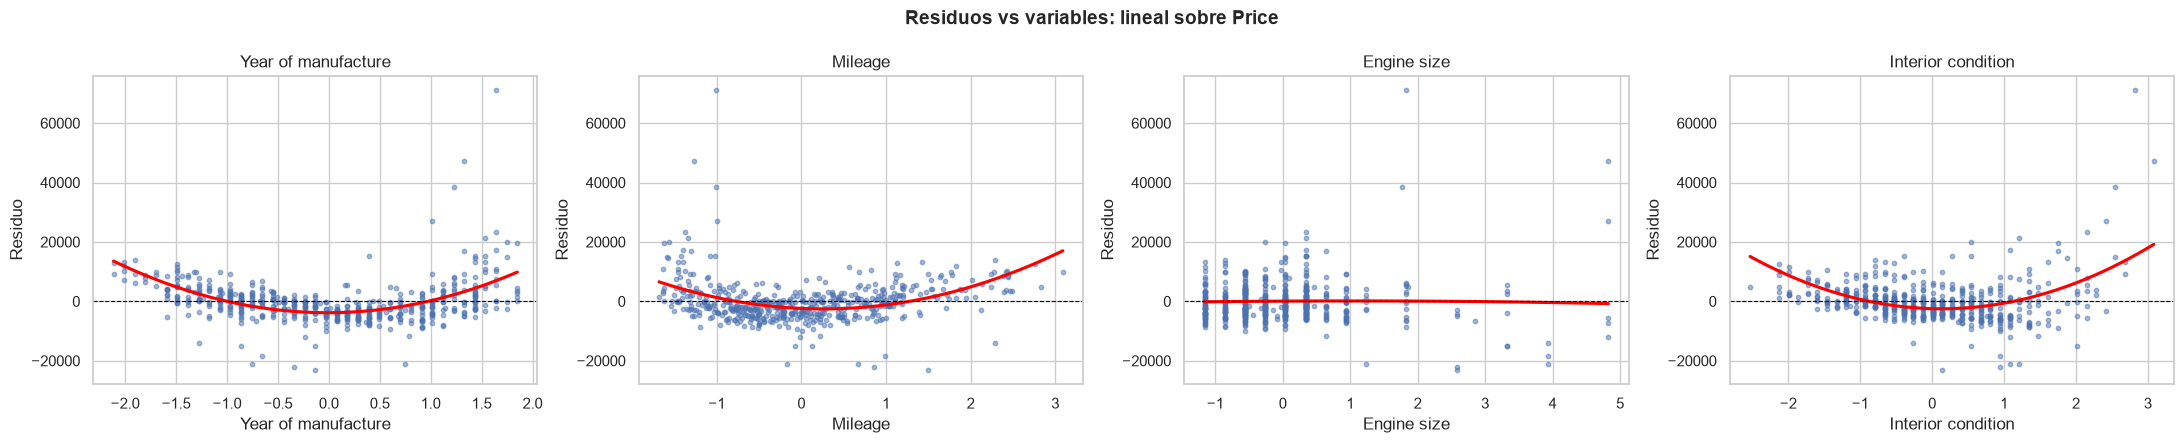

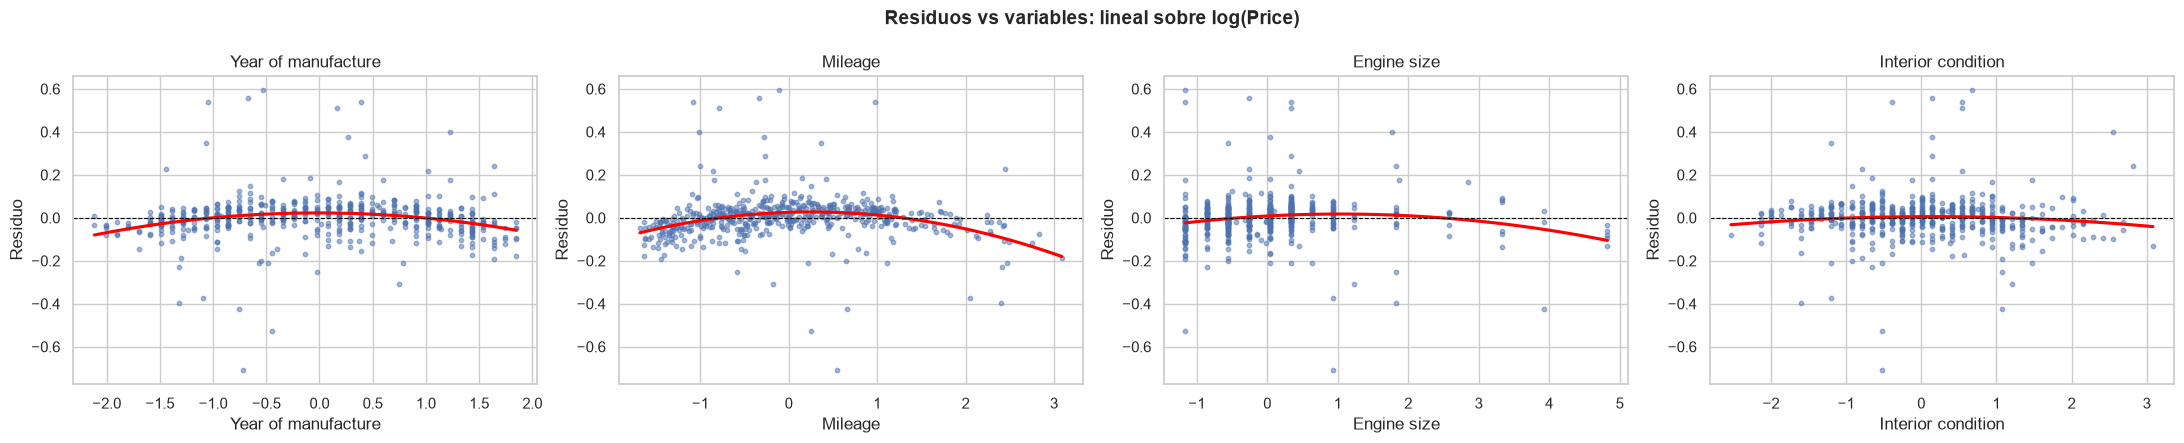

In [28]:
def residuos_vs_variables(residuos, Xdatos, titulo, variables=("Year of manufacture", "Mileage", "Engine size", "Interior condition")):
    fig, axes = plt.subplots(1, len(variables), figsize=(22, 4.5))
    for ax, var in zip(axes, variables):
        sns.regplot(x=Xdatos[var], y=residuos, order=2, ci=None, ax=ax, scatter_kws={"s": 10, "alpha": 0.5}, line_kws={"color": "red"})
        ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
        ax.set_title(var)
        ax.set_ylabel("Residuo")
    fig.suptitle(titulo, fontweight="bold", fontsize=14)
    plt.tight_layout()
    plt.show()

residuos_vs_variables(Y_train - lr_raw.predict(X_train), X_train, "Residuos vs variables: lineal sobre Price")
residuos_vs_variables(Y_train_log - lr_log.predict(X_train), X_train, "Residuos vs variables: lineal sobre log(Price)")



Residuos frente a las variables:
- En el modelo sobre `Price`, la parábola roja muestra una **curvatura muy clara** frente a `Year of manufacture`, `Mileage` e `Interior condition`. La relación con el precio no es lineal
- En el modelo sobre `log(Price)` las curvas son casi planas. Solo queda una ligera curvatura cóncava en `Mileage`, a kilometrajes muy altos el modelo sobreestima un poco el precio

La transformación logarítmica resuelve casi todo el problema, pero la curvatura en el modelo sin transformar y la ligera curvatura restante son lo que se intenta corregir en el apartado d) con interacciones.

# Apartado c) Ridge y LASSO

`RidgeCV` y `LassoCV` prueban una rejilla de valores de `alpha` y eligen el que da menor error en validación cruzada (5 folds) **dentro de train**. Ajusto sobre `log(Price)` porque ya he visto que es la escala adecuada.

In [29]:
ridge = RidgeCV(alphas=np.logspace(-4, 4, 100), cv=5).fit(X_train, Y_train_log)
lasso = LassoCV(alphas=np.logspace(-4, 4, 100), cv=5, max_iter=50000, random_state=1234).fit(X_train, Y_train_log)
print(f"alpha Ridge: {ridge.alpha_:.4f}")
print(f"alpha LASSO: {lasso.alpha_:.6f}\n")

metricas_c = pd.DataFrame({
    "Lineal": evaluar(lr_log, X_train, X_test, log=True),
    "Ridge": evaluar(ridge, X_train, X_test, log=True),
    "LASSO": evaluar(lasso, X_train, X_test, log=True),
})
metricas_c.loc["Pesos = 0"] = [0, (ridge.coef_ == 0).sum(), (lasso.coef_ == 0).sum()]
metricas_c.round(3)

alpha Ridge: 0.0001
alpha LASSO: 0.000100



,Lineal,Ridge,LASSO
R2 train,0.970,0.970,0.969
R2 test,0.987,0.987,0.987
RMSE test,1828.848,1828.838,1830.368
MAE test,877.954,877.938,883.110
MAPE test (%),7.295,7.295,7.304
Pesos = 0,0.000,0.000,0.000


Con el logaritmo, la validación cruzada elige el alpha más pequeño de la rejilla en ambos casos, la regularización óptima es nula. Por eso las métricas de los tres modelos son idénticas (o peores en comparación al modelo base). Tiene sentido, sin colinealidad, el modelo lineal no sufre sobreajuste (train y test dan resultados muy parecidos), así que no hay varianza que reducir regularizando.

,Lineal,Ridge,LASSO,Lineal - Ridge
Model_Fiesta,-0.7164,-0.7163,-0.6452,-0.0001
Model_Polo,-0.6773,-0.6772,-0.6022,-0.0001
Mileage,-0.5353,-0.5353,-0.5354,0.0000
Model_Yaris,-0.5340,-0.5339,-0.4559,-0.0001
Model_Golf,-0.4554,-0.4554,-0.3820,-0.0001
Model_Mondeo,-0.2696,-0.2695,-0.2013,-0.0001
Model_Prius,-0.2624,-0.2623,-0.1844,-0.0001
Model_Focus,-0.2373,-0.2373,-0.1706,-0.0001
Model_Passat,-0.2277,-0.2276,-0.1530,-0.0001
Model_Z4,-0.1657,-0.1657,-0.1104,-0.0001


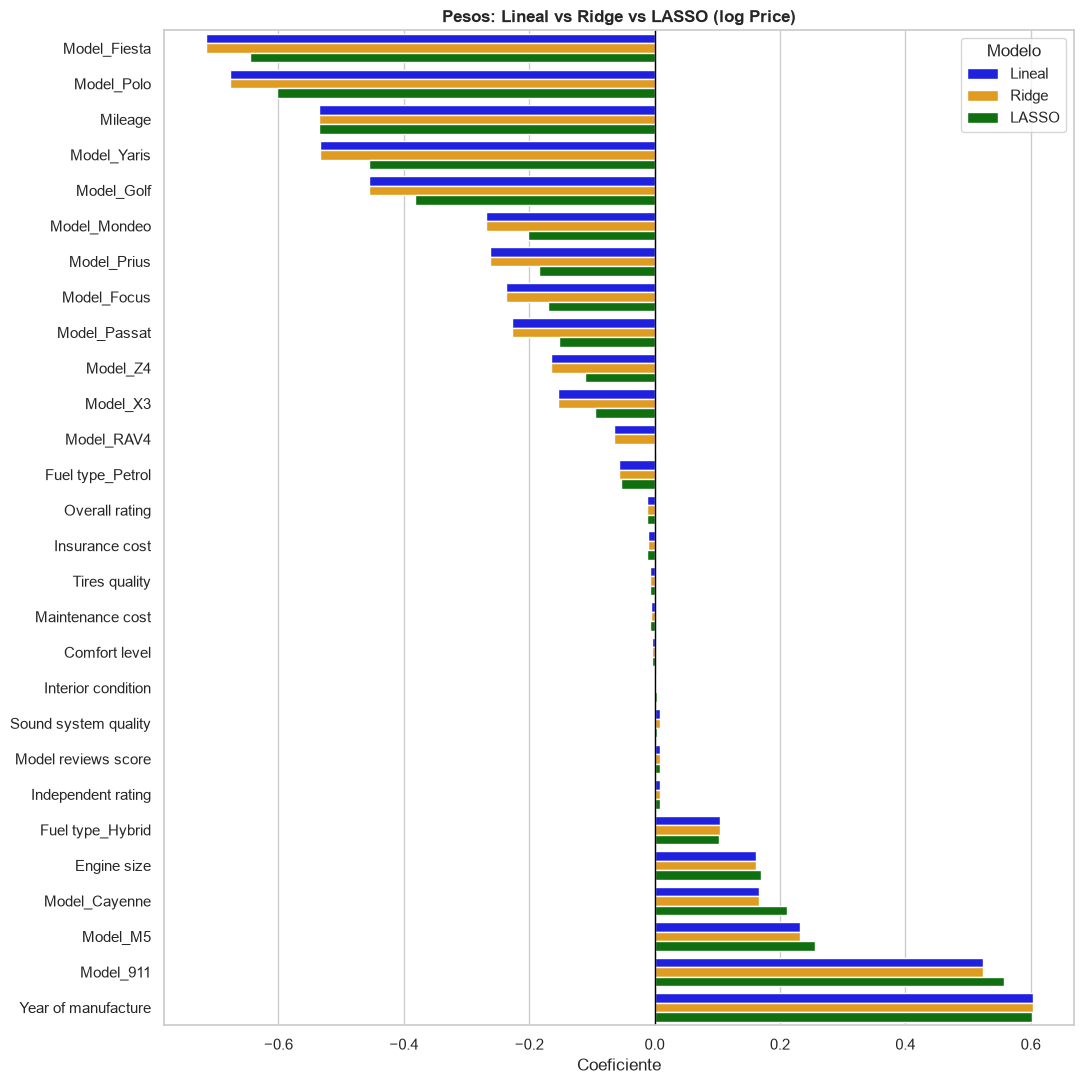

In [30]:
pesos = pd.DataFrame({"Lineal": lr_log.coef_, "Ridge": ridge.coef_, "LASSO": lasso.coef_}, index=X_train.columns)
pesos["Lineal - Ridge"] = pesos["Lineal"] - pesos["Ridge"]
pesos = pesos.sort_values("Lineal")
display(pesos.round(4))
pesos_largo = (pesos[["Lineal", "Ridge", "LASSO"]].reset_index(names="Variable").melt(id_vars="Variable", var_name="Modelo", value_name="Peso"))

plt.figure(figsize=(11, 11))
sns.barplot(data=pesos_largo, x="Peso", y="Variable", hue="Modelo", order=pesos.index, palette=["blue", "orange", "green"])
plt.axvline(0, color="black", linewidth=1)
plt.title("Pesos: Lineal vs Ridge vs LASSO (log Price)", fontweight="bold")
plt.xlabel("Coeficiente")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Lineal vs Ridge:** los pesos son **prácticamente idénticos**. La mayor diferencia es de 0.0001, porque el alpha elegido es casi 0. Esto indica que los pesos del modelo lineal son estables y no están "inflados" por colinealidad, y Ridge no tiene nada que corregir.

### Camino de regularización de LASSO

El `alpha` elegido por validación cruzada es muy pequeño, así que LASSO apenas elimina variables. Para ver qué variables considera prescindibles el modelo represento el camino de regularización (cómo evoluciona cada peso al aumentar `alpha`) y el error de validación cruzada. Además utilizo la regla de 1 error estándar, el `alpha` más grande cuyo error de CV no supera el mínimo más un error estándar. Da un modelo más simple con un rendimiento estadísticamente equivalente.

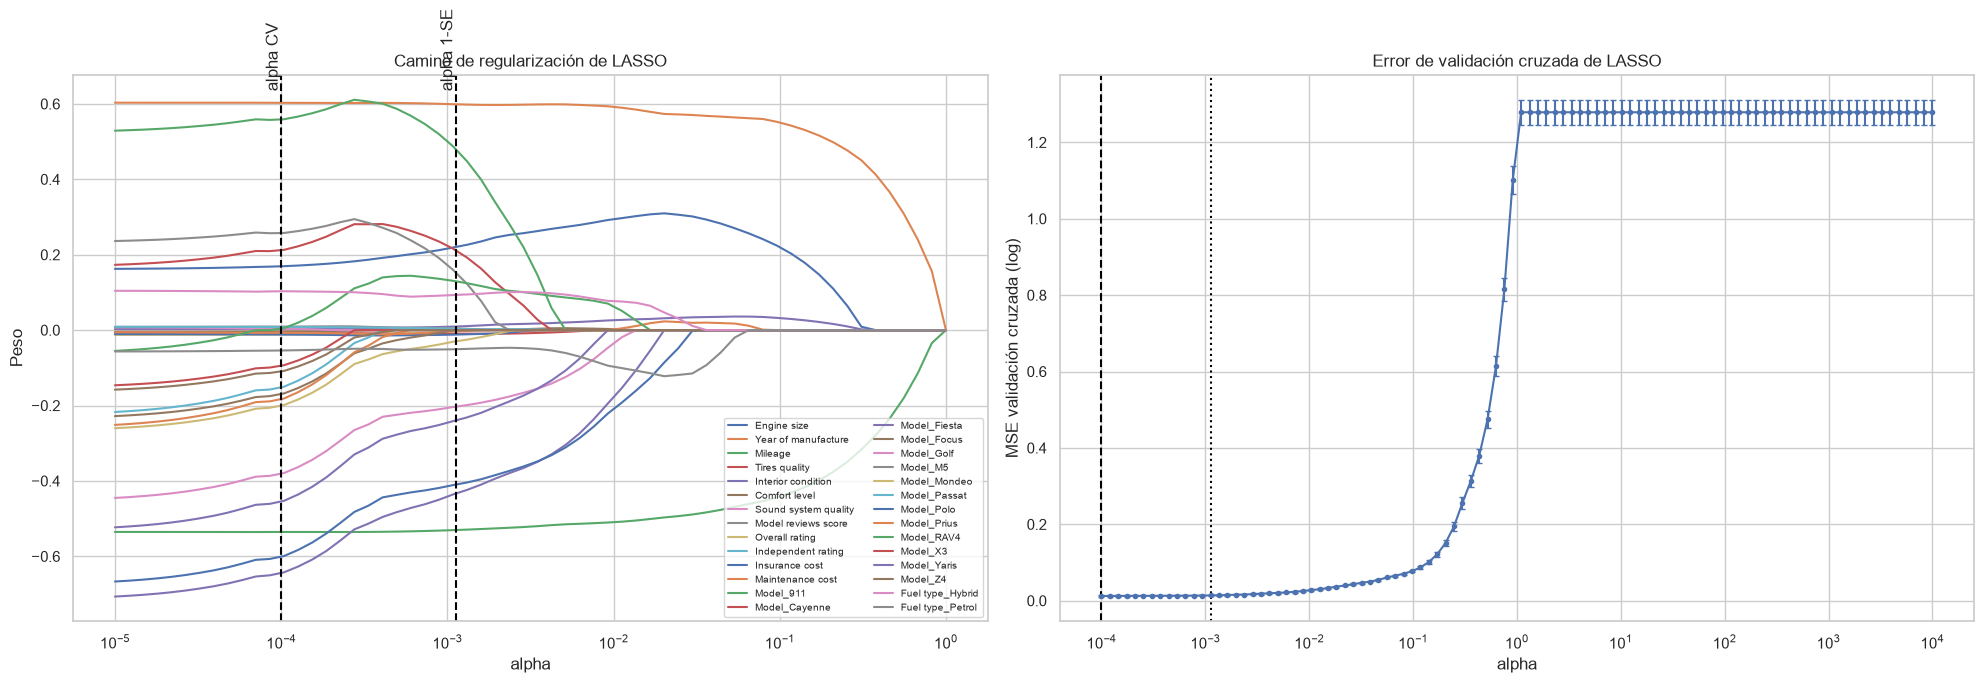

alpha 1-SE: 0.00112
Variables eliminadas con alpha CV (0): []
Variables eliminadas con alpha 1-SE (7): ['Comfort level', 'Sound system quality', 'Model_Focus', 'Model_Passat', 'Model_Prius', 'Model_X3', 'Model_Z4']


,LASSO (alpha CV),LASSO (alpha 1-SE)
R2 train,0.969,0.954
R2 test,0.987,0.984
RMSE test,1830.368,2047.942
MAE test,883.110,974.251
MAPE test (%),7.304,7.569


In [31]:
mse_medio = lasso.mse_path_.mean(axis=1)
mse_se = lasso.mse_path_.std(axis=1) / np.sqrt(lasso.mse_path_.shape[1])
idx_min = np.argmin(mse_medio)
alpha_1se = lasso.alphas_[mse_medio <= mse_medio[idx_min] + mse_se[idx_min]].max()

alphas_camino = np.logspace(-5, 0, 60)
camino = pd.DataFrame([Lasso(alpha=a, max_iter=50000).fit(X_train, Y_train_log).coef_ for a in alphas_camino], index=alphas_camino, columns=X_train.columns)

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
for col in camino.columns:
    axes[0].plot(camino.index, camino[col], label=col)
for a, txt in [(lasso.alpha_, "alpha CV"), (alpha_1se, "alpha 1-SE")]:
    axes[0].axvline(a, color="black", linestyle="--")
    axes[0].text(a, axes[0].get_ylim()[1]*0.95, txt, rotation=90, ha="right")
axes[0].set_xscale("log")
axes[0].set_xlabel("alpha")
axes[0].set_ylabel("Peso")
axes[0].set_title("Camino de regularización de LASSO")
axes[0].legend(fontsize=7, ncol=2, loc="lower right")
axes[1].errorbar(lasso.alphas_, mse_medio, yerr=mse_se, fmt="o-", markersize=3, capsize=2)
axes[1].axvline(lasso.alpha_, color="black", linestyle="--")
axes[1].axvline(alpha_1se, color="black", linestyle=":")
axes[1].set_xscale("log")
axes[1].set_xlabel("alpha")
axes[1].set_ylabel("MSE validación cruzada (log)")
axes[1].set_title("Error de validación cruzada de LASSO")
plt.tight_layout()
plt.show()

lasso_1se = Lasso(alpha=alpha_1se, max_iter=50000).fit(X_train, Y_train_log)
print(f"alpha 1-SE: {alpha_1se:.5f}")
print(f"Variables eliminadas con alpha CV ({(lasso.coef_ == 0).sum()}): {list(X_train.columns[lasso.coef_ == 0])}")
print(f"Variables eliminadas con alpha 1-SE ({(lasso_1se.coef_ == 0).sum()}): {list(X_train.columns[lasso_1se.coef_ == 0])}")
pd.DataFrame({"LASSO (alpha CV)": evaluar(lasso, X_train, X_test, log=True), "LASSO (alpha 1-SE)": evaluar(lasso_1se, X_train, X_test, log=True)}).round(3)

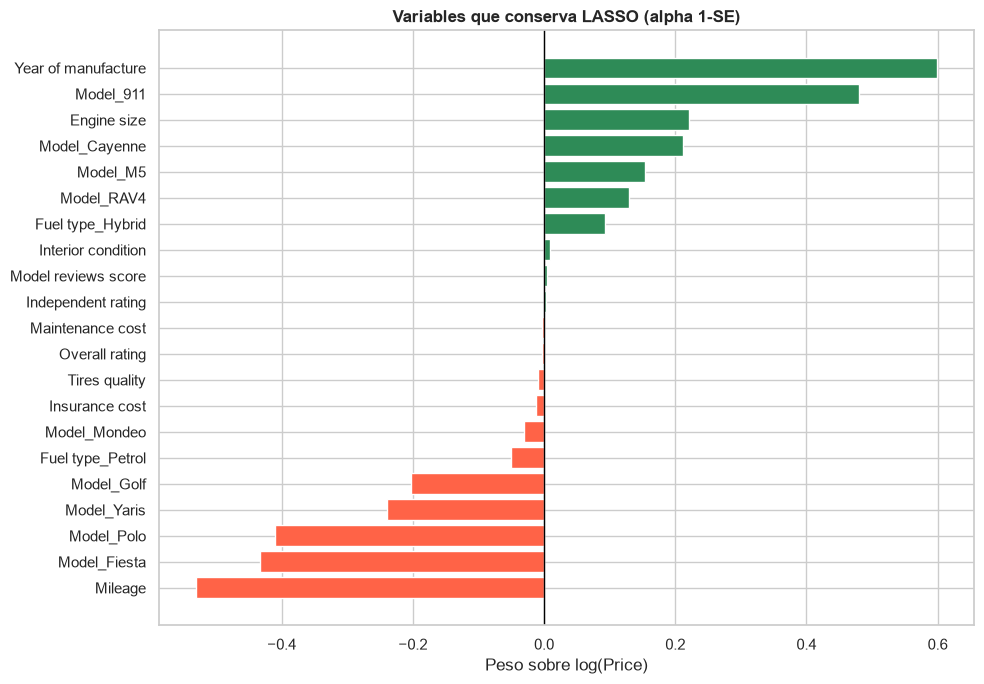

In [32]:
pesos_lasso = pd.Series(lasso_1se.coef_, index=X_train.columns)
pesos_lasso = pesos_lasso[pesos_lasso != 0].sort_values()
plt.figure(figsize=(10, 7))
plt.barh(pesos_lasso.index, pesos_lasso.values, color=["tomato" if p < 0 else "seagreen" for p in pesos_lasso])
plt.axvline(0, color="black", linewidth=1)
plt.title("Variables que conserva LASSO (alpha 1-SE)", fontweight="bold")
plt.xlabel("Peso sobre log(Price)")
plt.tight_layout()
plt.show()

Al aumentar `alpha` los pesos se van anulando. Los primeros en desaparecer son las valoraciones (sonido, reseñas, confort, neumáticos etc...), que caen a 0 en cuanto alpha crece un poco. Después se van anulando las dummy de modelo. Las últimas en sobrevivir son **`Year of manufacture`** (hasta alpha $\approx$ 1), **`Mileage`** y **`Engine size`**. Este orden es un ranking de importancia de las variables.

La curva de error de CV es plana hasta alpha $\approx$ $10^{-3}$, así que podemos regularizar bastante sin perder precisión. Con alpha 1-SE ($1.12·10^{-3}$) LASSO **elimina 7 variables**: `Comfort level`, `Sound system quality`, `Model_Focus`, `Model_Passat`, `Model_Prius`, `Model_X3` y `Model_Z4`. Además deja las demás valoraciones y `Maintenance cost` con pesos casi nulos. El rendimiento apenas cambia ($R^2$ test 0.984 frente a 0.987, MAPE 7.6% frente a 7.3%).

Las variables desaparecen debido a que:
- **`Comfort level` y `Sound system quality`**: ya vimos que no tienen relación con el precio una vez conocidos año y km, y además son redundantes con el resto de valoraciones
- **`Focus`, `Passat`, `Prius`, `X3` y `Z4`** (y casi `Mondeo`): son los modelos de gama media, con pesos intermedios (-14% a -23%). LASSO los elimina con la categoría de referencia y crea un único grupo de gama media. El efecto que se pierde lo absorbe en parte **`Engine size`**, que sube de 0.16 a 0.22 (un X3 o un Z4 tienen motores más grandes que un Passat). LASSO solo conserva separados los extremos, gama alta (`911`, `Cayenne`, `M5`, `RAV4`) y utilitarios o gama baja (`Fiesta`, `Polo`, `Yaris`, `Golf`)

**Tienen sentido las variables con más y menos peso?** Sí, el modelo explica el precio de un coche de forma muy intuitiva:
1. **Cuántos años tiene**
2. **Cuántos kilómetros lleva**
3. **Qué coche es**: la gama del modelo (deportivo/premium, gama media o utilitario) y el tamaño del motor
4. En menor medida, el **combustible** (los híbridos valen más)

Por el contrario, las **valoraciones subjetivas** (reseñas, sonido, confort, puntuación general etc...) y los costes de seguro y mantenimiento **no influyen** en el precio. Es lo que haría un tasador real, él miraría la ficha del coche (modelo, año, km, motor), no las opiniones.

# Apartado d) Interacciones con PolynomialFeatures

En el apartado b) vimos que la regresión lineal sobre el precio original deja un patrón muy claro en los residuos: **forma de U (parábola)** frente a la predicción y frente al año. Eso indica que la relación entre las variables y el precio no es aditiva, por ejemplo, un año más de antigüedad no resta los mismos euros a un Porsche 911 que a un Ford Fiesta, y el kilometraje penaliza distinto según el año.

`PolynomialFeatures(degree=2)` añade todos los productos de dos variables $x_i x_j$ (interacciones) y los cuadrados $x_i^2$. Detalles que tengo en cuenta:
- Con variables dummy, $x_i^2 = x_i$ (duplicado) y el producto de dos dummies excluyentes (dos modelos distintos) es siempre 0. Elimino  esas columnas constantes o duplicadas porque no aportan nada
- Volvemos a estandarizar tras crear las variables, los productos tienen escalas muy distintas y Ridge/LASSO necesitan variables comparables
- Con tantas variables como datos, la regresión sin regularizar sobreajustaría, por eso aplicaremos Ridge y LASSO

Ajustamos los modelos **en las dos escalas** del objetivo: sobre `Price` (donde estaba el problema de los residuos) y sobre `log(Price)` (nuestro mejor modelo hasta ahora).

In [33]:
poly = PolynomialFeatures(degree=2, include_bias=False).set_output(transform="pandas")
P_train = poly.fit_transform(X_train)
P_test = poly.transform(X_test)
print(f"Variables generadas: {P_train.shape[1]}")

# Quitamos columnas constantes (productos de dummies excluyentes) y duplicadas (cuadrados de dummies)
utiles = P_train.columns[P_train.std() > 0]
P_train = P_train[utiles].T.drop_duplicates().T
P_test = P_test[P_train.columns]
print(f"Variables tras eliminar constantes y duplicadas: {P_train.shape[1]}  (filas de train: {P_train.shape[0]})")

scaler_poly = StandardScaler().set_output(transform="pandas")
P_train = scaler_poly.fit_transform(P_train)
P_test = scaler_poly.transform(P_test)

Variables generadas: 434
Variables tras eliminar constantes y duplicadas: 313  (filas de train: 519)


In [34]:
alphas_ridge = np.logspace(-3, 5, 100)
ridge_p_raw = RidgeCV(alphas=alphas_ridge, cv=5).fit(P_train, Y_train)
lasso_p_raw = LassoCV(alphas=np.logspace(-1, 4, 80), cv=5, max_iter=100000, random_state=1234).fit(P_train, Y_train)
ridge_p_log = RidgeCV(alphas=alphas_ridge, cv=5).fit(P_train, Y_train_log)
lasso_p_log = LassoCV(alphas=np.logspace(-5, 0, 80), cv=5, max_iter=100000, random_state=1234).fit(P_train, Y_train_log)

ridge_raw = RidgeCV(alphas=alphas_ridge, cv=5).fit(X_train, Y_train)
lasso_raw = LassoCV(alphas=np.logspace(-1, 4, 80), cv=5, max_iter=100000, random_state=1234).fit(X_train, Y_train)

filas = {
    ("Price", "Lineal", "Grado 1"): evaluar(lr_raw, X_train, X_test),
    ("Price", "Ridge", "Grado 1"): evaluar(ridge_raw, X_train, X_test),
    ("Price", "LASSO", "Grado 1"): evaluar(lasso_raw, X_train, X_test),
    ("Price", "Ridge", "Grado 2"): evaluar(ridge_p_raw, P_train, P_test),
    ("Price", "LASSO", "Grado 2"): evaluar(lasso_p_raw, P_train, P_test),
    ("log(Price)", "Lineal", "Grado 1"): evaluar(lr_log, X_train, X_test, log=True),
    ("log(Price)", "Ridge", "Grado 1"): evaluar(ridge, X_train, X_test, log=True),
    ("log(Price)", "LASSO", "Grado 1"): evaluar(lasso, X_train, X_test, log=True),
    ("log(Price)", "Ridge", "Grado 2"): evaluar(ridge_p_log, P_train, P_test, log=True),
    ("log(Price)", "LASSO", "Grado 2"): evaluar(lasso_p_log, P_train, P_test, log=True),
}
metricas_d = pd.DataFrame(filas).T
n_vars = {"Grado 1": X_train.shape[1], "Grado 2": P_train.shape[1]}
modelos_lasso = {("Price", "Grado 1"): lasso_raw, ("Price", "Grado 2"): lasso_p_raw, ("log(Price)", "Grado 1"): lasso, ("log(Price)", "Grado 2"): lasso_p_log}
metricas_d["Pesos != 0"] = [(modelos_lasso[(o, g)].coef_ != 0).sum() if m == "LASSO" else n_vars[g] for o, m, g in metricas_d.index]
metricas_d.index.names = ["Objetivo", "Modelo", "Features"]
print(f"alpha Ridge grado 2: Price={ridge_p_raw.alpha_:.3f}, log={ridge_p_log.alpha_:.4f}")
print(f"alpha LASSO grado 2: Price={lasso_p_raw.alpha_:.3f}, log={lasso_p_log.alpha_:.6f}")
metricas_d.round(3)

alpha Ridge grado 2: Price=33.516, log=19.1791
alpha LASSO grado 2: Price=60.927, log=0.006093


R2 train  R2 test  RMSE test  MAE test  \
Objetivo   Modelo Features                                           
Price      Lineal Grado 1      0.748    0.726   8405.926  5120.503   
           Ridge  Grado 1      0.729    0.708   8677.201  5118.903   
           LASSO  Grado 1      0.710    0.710   8651.311  5110.937   
           Ridge  Grado 2      0.985    0.884   5472.424  2289.987   
           LASSO  Grado 2      0.984    0.922   4485.088  2049.064   
log(Price) Lineal Grado 1      0.970    0.987   1828.848   877.954   
           Ridge  Grado 1      0.970    0.987   1828.838   877.938   
           LASSO  Grado 1      0.969    0.987   1830.368   883.110   
           Ridge  Grado 2      0.987    0.914   4700.110  1634.463   
           LASSO  Grado 2      0.979    0.977   2462.513   887.854   

                            MAPE test (%)  Pesos != 0  
Objetivo   Modelo Features                             
Price      Lineal Grado 1         304.797          28  
           Ridge  Grado 1         295.171          28  
           LASSO  Grado 1         262.456          11  
           Ridge  Grado 2         260.680         313  
           LASSO  Grado 2         191.022         102  
log(Price) Lineal Grado 1           7.295          28  
           Ridge  Grado 1           7.295          28  
           LASSO  Grado 1           7.304          28  
           Ridge  Grado 2          10.542         313  
           LASSO  Grado 2           6.926          45

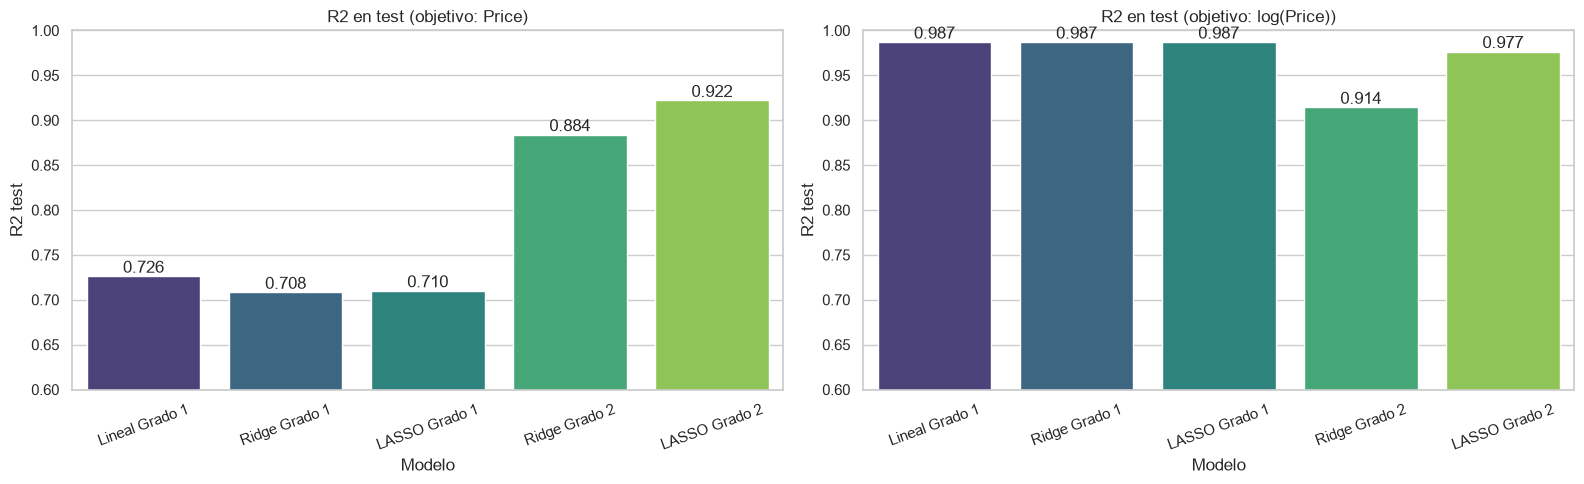

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
tabla = metricas_d.reset_index()
tabla["Modelo"] = tabla["Modelo"] + " " + tabla["Features"]
for ax, objetivo in zip(axes, ["Price", "log(Price)"]):
    t = tabla[tabla["Objetivo"] == objetivo]
    sns.barplot(data=t, x="Modelo", y="R2 test", ax=ax, palette="viridis", hue="Modelo", legend=False)
    ax.set_ylim(0.6, 1)
    ax.set_title(f"R2 en test (objetivo: {objetivo})")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

Sobre `Price`: **sí, ha mejorado bastante.** El $R^2$ de test pasa de 0.71-0.73 a **0.92 con LASSO** (0.88 con Ridge), el MAE baja de $\approx 5.100$ € a **$\approx 2.050$ €** y el MAPE de $\approx 300$% a **$191$%**. Las interacciones permiten modelar los efectos no aditivos que el modelo lineal no podía capturar. Aun así:
- El MAPE sigue siendo altísimo porque el modelo sigue dando valores negativos o cercanos a 0 para algunos coches muy baratos
- Hay un poco de **sobreajuste**: $R^2$ de 0.98 en train frente a 0.88-0.92 en test

*Sobre `log(Price)`:* **no mejoran de forma clara.**
- **LASSO grado 2** obtiene un MAPE algo mejor (6.9% frente a 7.3%) y un MAE parecido (888 € frente a 878 €), pero un $R^2$ y un RMSE peores (0.977 frente a 0.987, 2.460 € frente a 1.830 €). Acierta un poco mejor la mayoría de coches y falla más en algunos caros
- **Ridge grado 2 empeora claramente** ($R^2$ test 0.914, MAPE 10.5%) por sobreajuste: $R^2$ de train de 0.987 pero mucho peor en test. Con 313 variables para 519 coches, Ridge no puede anular las interacciones inútiles, solo encogerlas. LASSO sí las elimina y aguanta mejor (puede poner los pesos a 0)

**Conclusión:** el modelo más equilibrado sigue siendo la **regresión lineal de grado 1 sobre `log(Price)`**. Las interacciones de grado 2 solo aproximan lo que el logaritmo ya hace de forma exacta: en escala log, el efecto de cada variable es un porcentaje, y eso en escala original equivale a interacciones entre todas las variables. Con el logaritmo apenas quedan interacciones relevantes que añadir.

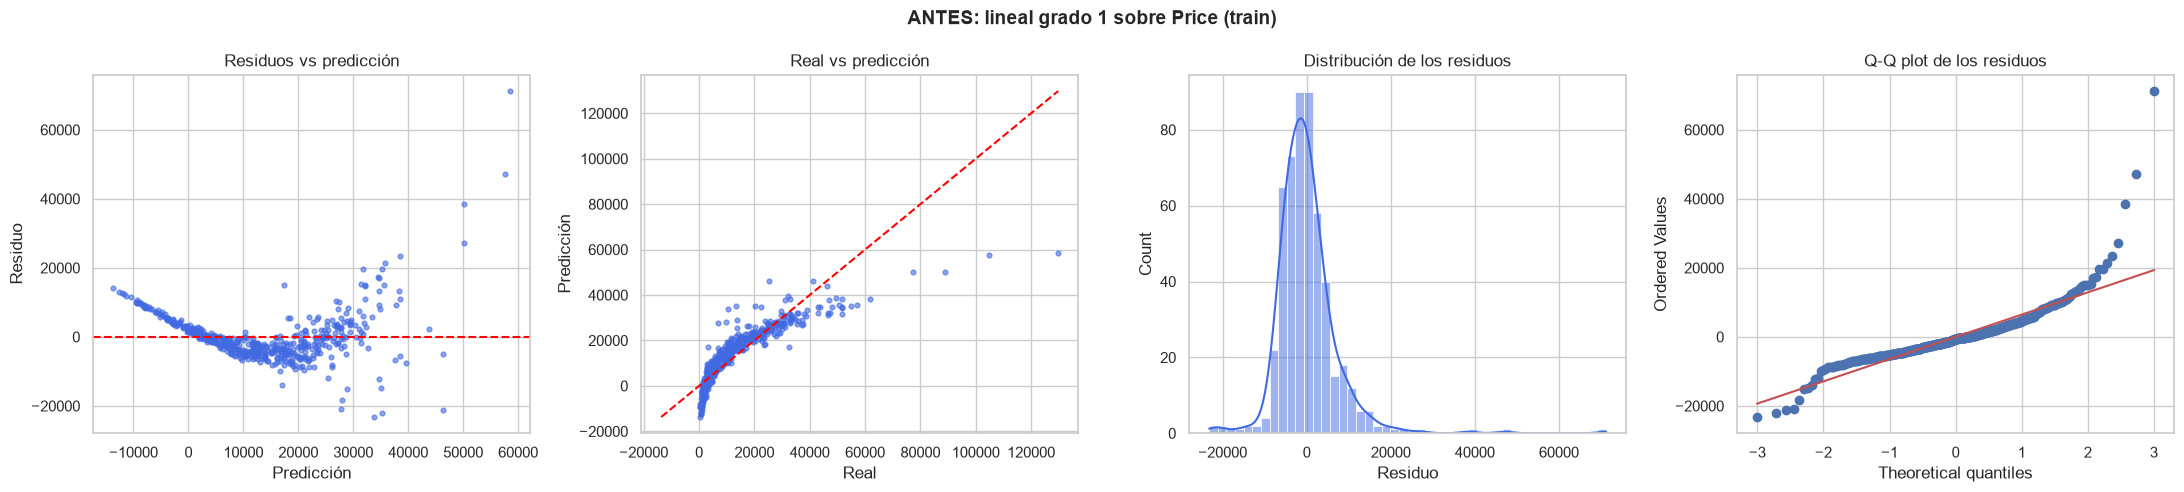

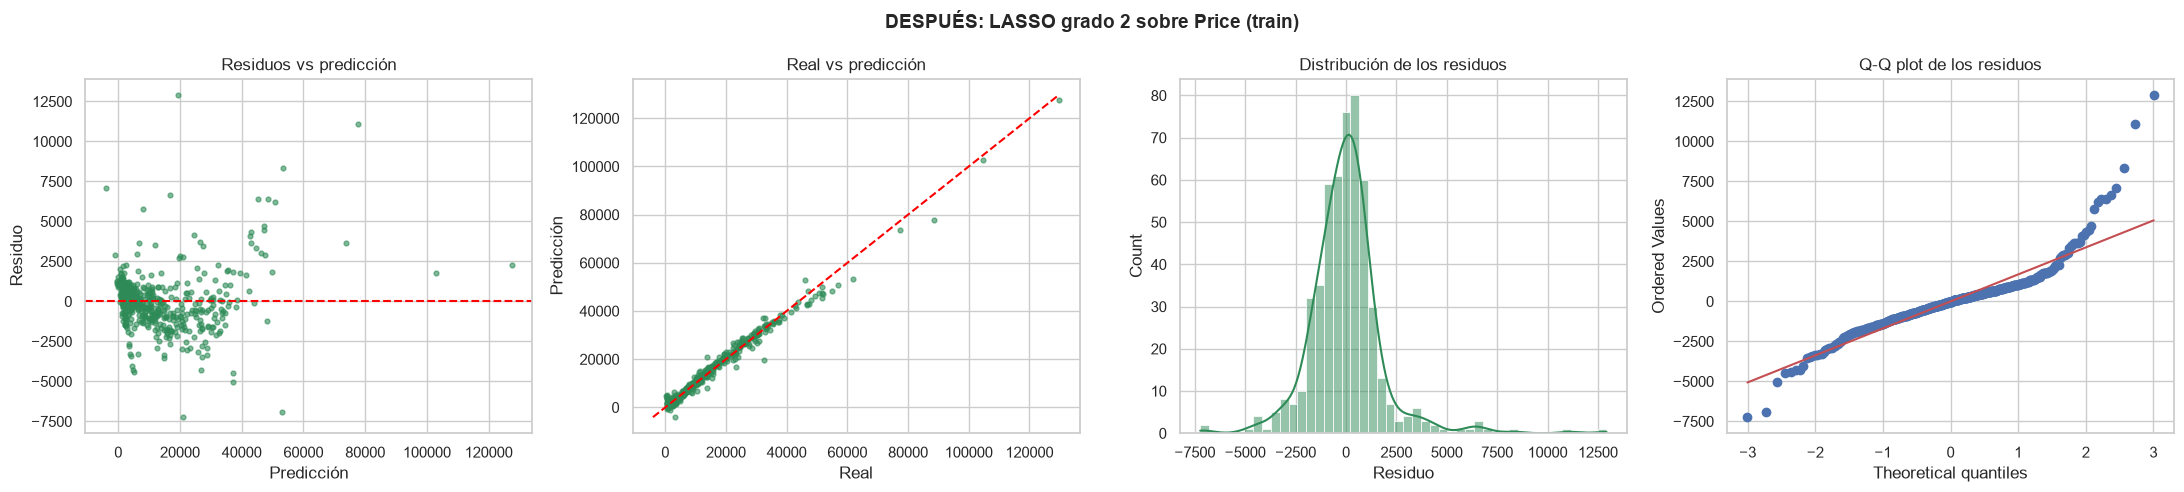

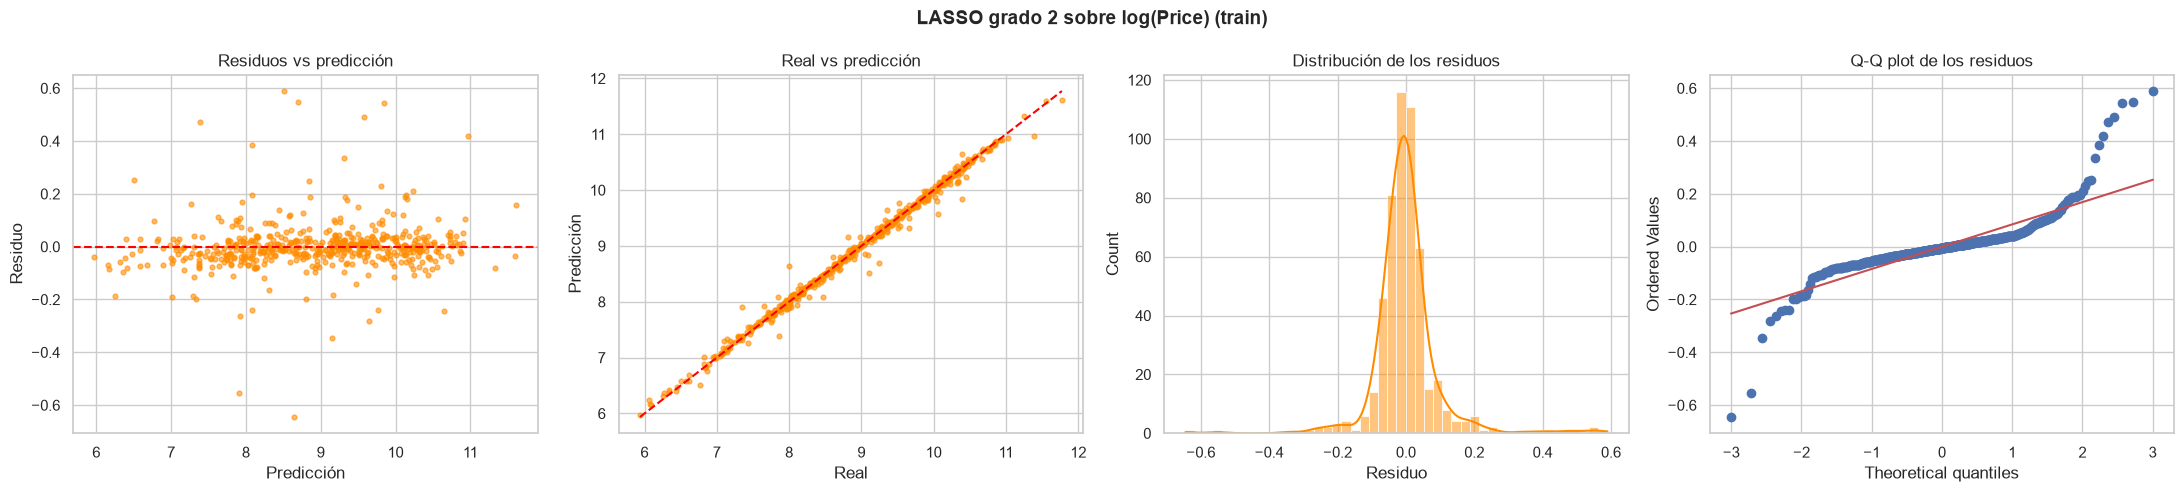

In [36]:
graficar_residuos(Y_train, lr_raw.predict(X_train), "ANTES: lineal grado 1 sobre Price (train)")
graficar_residuos(Y_train, lasso_p_raw.predict(P_train), "DESPUÉS: LASSO grado 2 sobre Price (train)", color="seagreen")
graficar_residuos(Y_train_log, lasso_p_log.predict(P_train), "LASSO grado 2 sobre log(Price) (train)", color="darkorange")

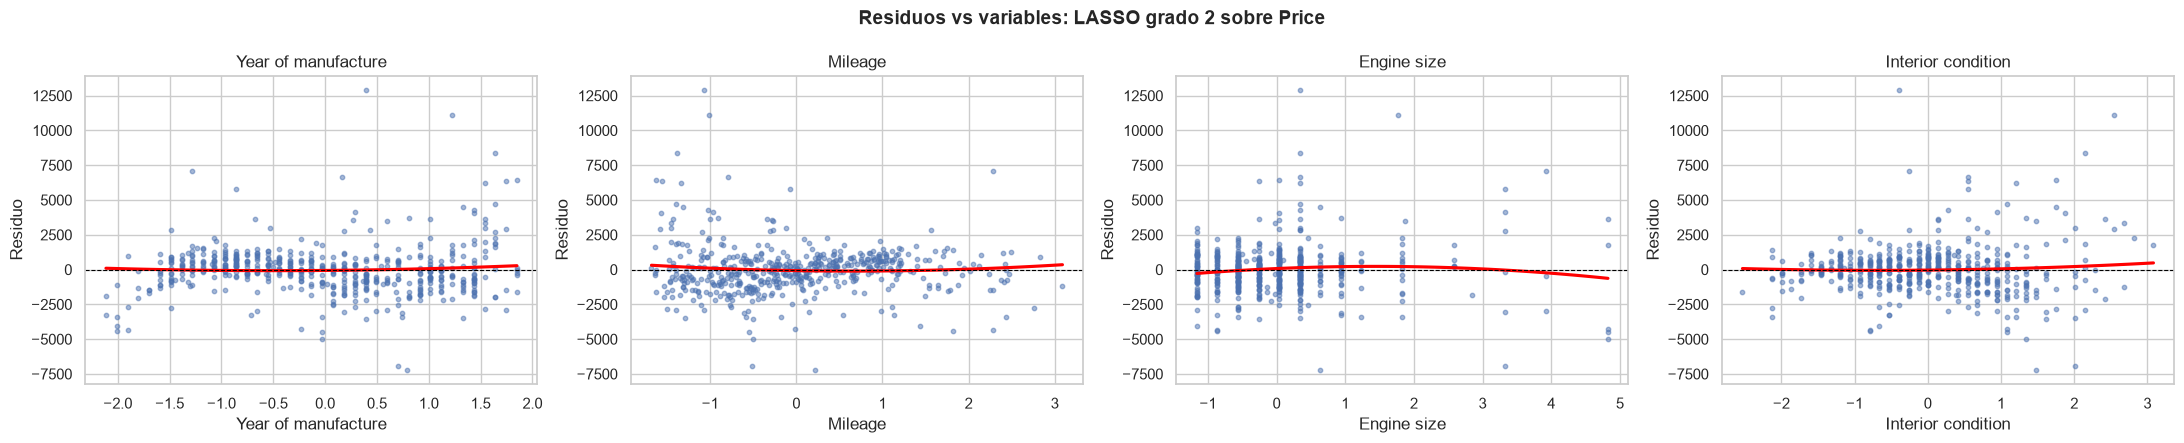

In [37]:
residuos_vs_variables(Y_train - lasso_p_raw.predict(P_train), X_train, "Residuos vs variables: LASSO grado 2 sobre Price")

**¿Se ha arreglado el problema de los residuos?**

- **Sobre `Price`: sí, en gran parte.** La forma de **U** de los residuos frente a la predicción ha **desaparecido**, los residuos están centrados en 0 en todo el rango y su magnitud baja mucho. En "Real vs predicción" los puntos siguen la diagonal en lugar de una curva. Frente a `Year`, `Mileage` e `Interior condition` las parábolas rojas son ahora **planas**, cuando antes eran claramente curvas. Queda algo de **heterocedasticidad** (los residuos se abren en forma de embudo cuando el precio es alto) y algunas predicciones ligeramente negativas para coches muy baratos. Son síntomas de que el error es proporcional al precio, algo que solo resuelve el logaritmo.
- **Sobre `log(Price)`:** los residuos eran ya buenos antes y siguen igual, con colas pesadas causadas por los mismos coches atípicos. Las interacciones no los explican, su precio debe depender de algo que no está en los datos.

LASSO grado 2 sobre Price: 102 de 313 variables con peso != 0 -> {'interacción': 84, 'original': 12, 'cuadrado': 6}
   Originales que elimina: ['Tires quality', 'Comfort level', 'Sound system quality', 'Model reviews score', 'Overall rating', 'Independent rating', 'Insurance cost', 'Maintenance cost', 'Model_911', 'Model_Focus', 'Model_M5', 'Model_Mondeo', 'Model_Passat', 'Model_Prius', 'Model_X3', 'Model_Z4']
LASSO grado 2 sobre log(Price): 45 de 313 variables con peso != 0 -> {'interacción': 30, 'original': 14, 'cuadrado': 1}
   Originales que elimina: ['Comfort level', 'Sound system quality', 'Model reviews score', 'Overall rating', 'Independent rating', 'Insurance cost', 'Maintenance cost', 'Model_911', 'Model_Focus', 'Model_Mondeo', 'Model_Passat', 'Model_Prius', 'Model_X3', 'Model_Z4']


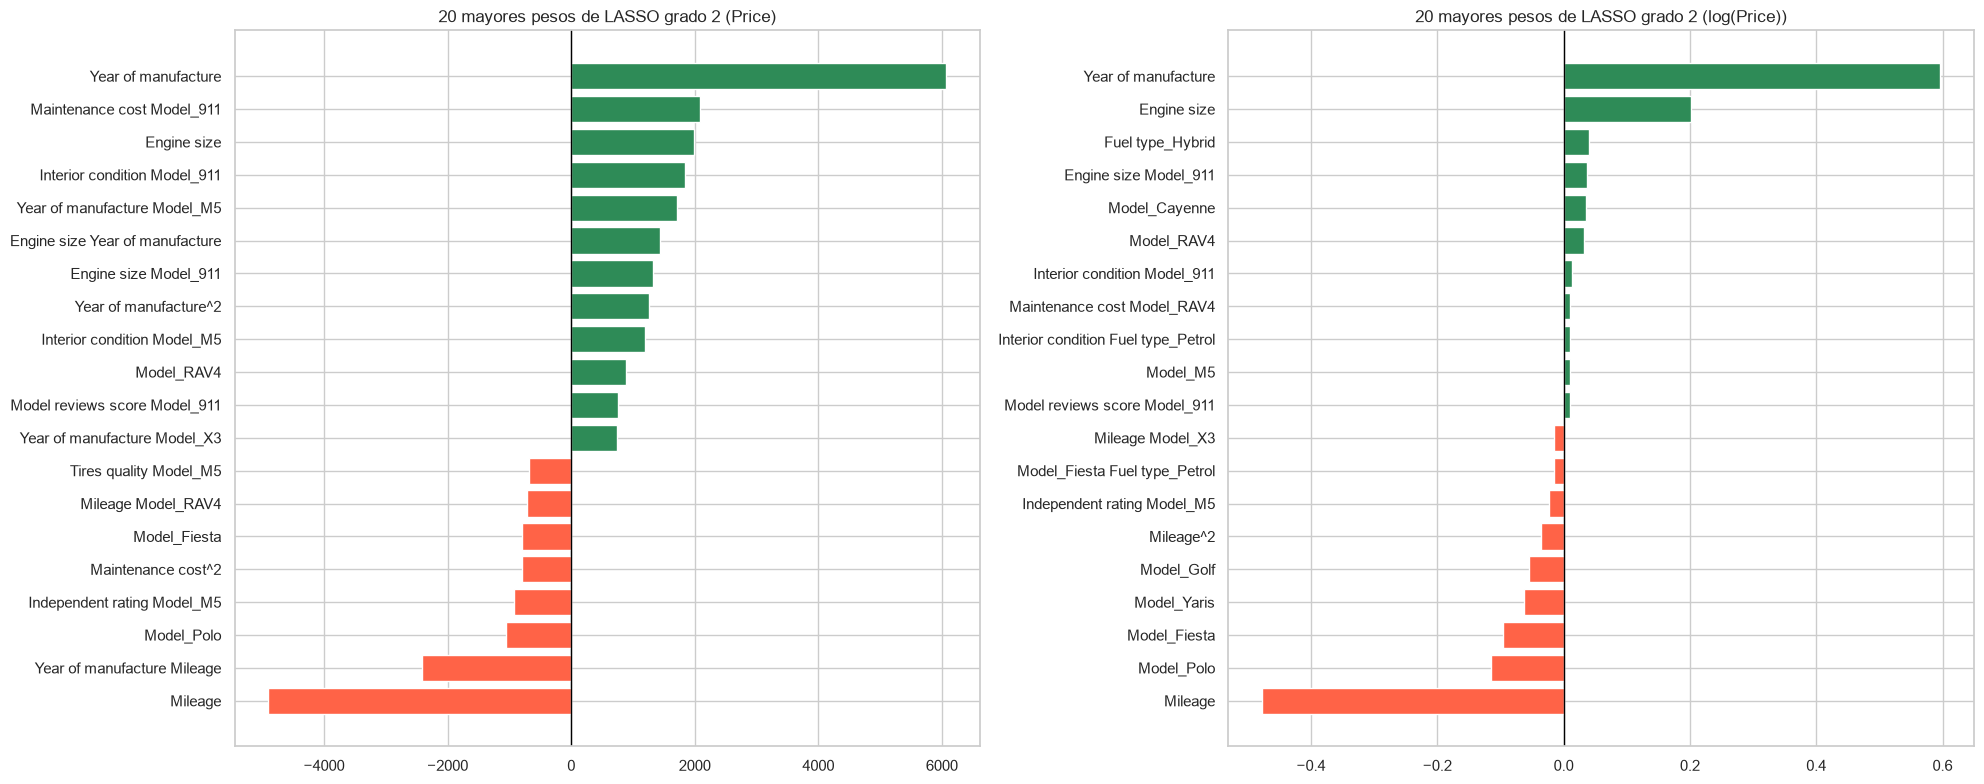

In [38]:
tipo = {nombre: "original" if pot.sum() == 1 else ("cuadrado" if pot.max() == 2 else "interacción") for nombre, pot in zip(poly.get_feature_names_out(), poly.powers_)}
for nombre, mod in [("Price", lasso_p_raw), ("log(Price)", lasso_p_log)]:
    coef = pd.Series(mod.coef_, index=P_train.columns)
    coef = coef[coef != 0]
    conteo = pd.Series([tipo[c] for c in coef.index]).value_counts().to_dict()
    print(f"LASSO grado 2 sobre {nombre}: {len(coef)} de {P_train.shape[1]} variables con peso != 0 -> {conteo}")
    print(f"   Originales que elimina: {[c for c in X_train.columns if c not in coef.index]}")

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, (nombre, mod) in zip(axes, [("Price", lasso_p_raw), ("log(Price)", lasso_p_log)]):
    coef = pd.Series(mod.coef_, index=P_train.columns)
    top = coef[coef.abs().sort_values(ascending=False).index[:20]].sort_values()
    ax.barh(top.index, top.values, color=["tomato" if v < 0 else "seagreen" for v in top])
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"20 mayores pesos de LASSO grado 2 ({nombre})")
plt.tight_layout()
plt.show()

- **Sobre `Price`:** se queda con **102 de 313 variables** (33%): 12 originales, 84 interacciones y 6 cuadrados. Es un modelo **complejo**. Las variables más importantes forman un esquema claro:
  - Efectos principales de `Year of manufacture`, `Mileage` y `Engine size`.
  - `Year x Mileage` (−) y $\texttt{Year}^2$ (+): la depreciación no es lineal. El coche pierde más euros en los primeros años, tal como haría una curva exponencial
  - `Engine size × Year` (+): un motor grande vale más cuanto más nuevo es el coche
  - Interacciones con los modelos caros (`Maintenance cost × 911`, `Interior condition × 911`, `Year × M5`, `Interior condition × M5` etc..): en un coche caro, cada característica supone muchos más euros

Esto confirma la explicación que he dado en el apartado b), **los efectos son multiplicativos** (el mismo porcentaje de depreciación supone muchos más euros en un coche caro)
- **Sobre `log(Price)`:** se queda con solo **45 de 313** (14%): 14 originales, 30 interacciones y 1 cuadrado. Los pesos importantes son casi los mismos que en el modelo lineal: `Year`, `Mileage`, `Engine size`, híbrido y las dummy de los modelos. Las interacciones tienen pesos muy pequeños (< 0.04), salvo $\texttt{Mileage}^2$ (−), que recoge la ligera curvatura en el km que vimos en los residuos del apartado b)

Comparado con el modelo log de grado 1 (28 variables, y 21 con alpha 1-SE), LASSO grado 2 es más complejo y menos interpretable, y solo mejora ligeramente el MAPE.

# Conclusiones

1. **Preprocesado (a):** `Inspection rating` se elimina por no tener varianza. `Insurance cost` es binaria. **`Manufacturer` se elimina** porque la marca se deduce del modelo, mantener las dos producía colinealidad perfecta. Los NaN se imputan con `KNNImputer` sobre variables estandarizadas. En el PCA, la dirección de **antigüedad/kilometraje (PC1)** ordena perfectamente los precios, mientras que la de mayor varianza (PC0, valoraciones) no está relacionada con el precio.
2. **Regresión lineal (b):** sobre el precio original el ajuste es pobre ($R^2$ 0.73, predicciones negativas, residuos en **forma de U**). Con **`log(Price)`** el modelo es excelente, **$R^2$ 0.987 y error medio del $\approx \texttt{7\%}$** en test. Los efectos son porcentuales: unos -6% por año, -41% por cada 68.000 km, y diferencias de gama entre modelos.
3. **Ridge y LASSO (c):** no mejoran la precisión porque el modelo lineal no sobreajusta, pero confirman qué variables importan. LASSO elimina las valoraciones subjetivas, agrupa los modelos de gama media y conserva **año, kilometraje, gama del modelo, motor y combustible**. El precio de un coche se explica por **lo que es y lo usado que está**, no por las opiniones sobre él.
4. **Interacciones (d):** sobre `Price`, `PolynomialFeatures` de grado 2 corrige la forma de U de los residuos y sube el $R^2$ de 0.73 a 0.92, pero a costa de un modelo con 102 variables poco interpretables. Sobre `log(Price)` apenas aporta, LASSO mejora un poco el MAPE y empeora el $R^2$, y Ridge empeora por sobreajuste.

**El mejor modelo es el lineal sobre `log(Price)`**, es igual o más preciso, mucho más simple y fácil de interpretar. La transformación logarítmica resuelve de raíz el problema que las interacciones solo resuelven de forma aproximada.